<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/28_QML_Hardware_Side_Channel_Crosstalk_Attacks/QNN_CrosstalkAttacks_Franco2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Crosstalk, noise and readout attacks on quantum neural networks: Franco et al. (2026, BSI "SecQML") step by step

This notebook re-implements, runs and checks the **empirical part on hardware noise, crosstalk, transpilation and readout
attacks** of the study

> Nicola Franco, Alona Sakhnenko, Leon Stolpmann, Jeanette Miriam Lorenz, Daniel Thuerck, Matthias Wulff, Lilian Do Khac,
> Christian Hammer, Fabian Petsch and Arthur Schmidt, "Security Aspects of Quantum Machine Learning (SecQML)",
> Federal Office for Information Security (BSI), Bonn, 2026. DOI 10.24406/h-508719

The study is a 120-page survey of the attack surface of quantum machine learning (QML) **plus a handful of new
experiments**. The survey chapters (2, 3, most of 4 and 8) contain nothing to run. The experiments of Chapters 5, 6.1.2, 6.2.2 and
7 all use one small quantum neural network (QNN) and are the subject of this notebook:

| Paper section | Experiment | Paper figure | Cell block here |
|---|---|---|---|
| 5.2.2 | **crosstalk-induced fault injection** on a victim QNN in a multi-tenant device (IBM Nairobi vs IBM Brisbane) | Fig. 32-35 | section 4 |
| 5.2.2 | noise amplification by falsified calibration data: QNN accuracy against noise level on three IBM backends | Fig. 36 | section 5 |
| 6.1.2 | transpiler **gate injection** (pairs of opposite rotations) | Fig. 41 | section 6 |
| 6.2.2 | parity-check defence against gate injection | Fig. 43-44 | section 6 |
| 7.2 | readout falsification by **reducing the number of shots** | Fig. 45 | section 7 |
| 7.3 | readout falsification by changing the Pauli basis or flipping returned bits | Fig. 46 | section 7 |
| 5.2.2 | circuit depth / gate counts of the QNN | Table 3 | section 3 |

**Not reproduced** (and why, in the table at the end): Chapter 4 (robust encodings for quantum kernels under adversarial
attack, a different experiment family), Section 6.1.1 (QTrojan on quantum kernels), Section 6.2.1 / Fig. 42 (approximate
transpilation with the QSearch synthesis tool from BQSKit, not available here), and everything that ran on **real IBM
hardware** (Nairobi and Brisbane runs in Fig. 34 and 35; those are replaced by a simulator, see the table of choices).

**What the notebook does.** (1) Builds the paper's two data sets (Iris, two classes, 4 amplitudes = 2 qubits; MNIST digits 1
vs 9 at 16 x 16 pixels = 256 amplitudes = 8 qubits). (2) Trains the paper's QNN (amplitude encoding + strongly entangling
layers, Table 3) in PennyLane, plus classical baselines on the same inputs. (3) Rebuilds the same circuit in Qiskit, checks
that both frameworks give the same probabilities and counts the circuit depth. (4) Simulates IBM devices with Qiskit Aer
noise models built from the fake-backend calibration data (Brisbane, Kyoto, Osaka, Nairobi) and runs every attack on them.
(5) Compares each statement of the paper with the number measured here.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs
pinned packages (a session restart may be requested, then run all again). `FAST_MODE = True` (training on a subset, fewer
test images and sweep points) finishes in under ten minutes; `FAST_MODE = False` follows the paper's training budgets
(Table 3: 50 epochs on all 10,152 MNIST-2 images) and takes about an hour on a laptop CPU (see the run time printed at the end).
The outputs stored in this file come from the run mode named in the first line of the configuration cell. No quantum hardware, account or API key is needed (`IBM_TOKEN` is optional and unused).

**What you get at the end.** Redrawn versions of Fig. 34-36, 41, 44, 45 and 46, a table of circuit statistics, and a table
that puts the paper's statements next to the numbers measured here with a verdict per statement.

## The paper in one page

**Problem.** QML adds three things to the attack surface of machine learning: the *encoding* of classical data into a
quantum state, the *execution* on (shared, cloud-hosted, noisy) quantum hardware through a *transpiler*, and the *read-out*
of measurement results. The study asks which of these steps an attacker can abuse and how much damage that does to a QNN
classifier.

**Threat models used in the experiments (Fig. 7 of the paper).** (i) A co-tenant on the same chip submits a "crosstalk
drive" circuit (repeated CNOTs) that disturbs the victim through qubit-qubit coupling. (ii) An attacker who controls the
calibration data or the transpiler falsifies noise information or injects gates that are mathematically
the identity (pairs of opposite rotations) but cost noise on hardware. (iii) An attacker who controls the configuration or
the channel between device and user reduces the shot count, changes the measurement basis, or flips returned bits.

**Victim model (Section 5.2.2, Table 3).** A QNN classifier: amplitude encoding of the input, `StronglyEntanglingLayers`
(Schuld et al.) with 2 layers, one measured qubit; Adam, learning rate 0.05; Iris: batch 30, 100 epochs, 2 qubits, 13
parameters; MNIST-2: batch 128, 50 epochs, 8 qubits.

**Data.** Iris with the versicolor class and the petal-width feature removed (100 vectors, 3 features padded with a zero
and L2-normalised; 60 train / 40 test). MNIST-2: digits 1 and 9 of MNIST, resized to 16 x 16, 12,691 images split
10,152 train / 2,285 validation / 254 test.

**Claims that can be tested without hardware.** Table 3 (depth 16 for Iris, 511 for MNIST-2); IBM Nairobi shows a
crosstalk effect, IBM Brisbane does not (Fig. 34); MNIST-2 is classified at random on the noisy backends with or without
attack (Fig. 35); the noise-level curves of Fig. 36 (e.g. amplitude damping at level 0.2 gives a random classifier,
depolarizing keeps accuracy above 0.9 up to 0.1, phase damping up to 0.3); Rz injection is harmless, Rx and Ry injection
destroys accuracy, Iris is more susceptible than MNIST-2 (Fig. 41); parity checking keeps accuracy stable (Fig. 44); shot
reduction hardly matters for Iris but does for MNIST-2 (Fig. 45); Pauli-X/Y read-out and bit flips lower accuracy,
MNIST-2 more than Iris (Fig. 46).

## What follows the paper and what had to be chosen

The paper ran the crosstalk experiments on real IBM processors and the other experiments on "simulated" IBM backends
without publishing code, noise parameters, shot counts or the exact loss. The table lists every place where this notebook had
to decide something. Each choice is also marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Crosstalk experiment | Real IBM Nairobi (Falcon r4H) and Brisbane (Eagle r3) hardware, 10 runs x 8000 shots | **Simulation** with the fake-backend calibration (gate errors, T1/T2, read-out errors) of `FakeNairobiV2` and `FakeBrisbane` plus an explicit crosstalk model (ZZ and ZX coupling between a driven attacker qubit and its coupled neighbours, strength set by a rate in kHz) |
| Crosstalk strength | Not given (it is a property of the chip) | `ZETA_KHZ = {Nairobi-like: 100, Brisbane-like: 5}` (an older Falcon pair with strong spill-over vs a weakly coupled Eagle pair; **an assumption**, the sweep in section 4 shows where the attack starts to work) |
| Which qubit is read out | Not stated | Wire 0, mapped to the physical qubit that touches the attacker (worst case); the other mapping is shown as a sensitivity row |
| Attacker circuit | "Hadamard and CNOT gates on the bottom two qubits", 35 gates after the victim | H followed by `K_CX = 30` CNOTs on two coupled qubits, transpiled without optimisation so that pairs of CNOTs are not cancelled |
| Loss / output | One-hot labels, one measurement, 13 parameters for Iris | Probability of outcome 1 on wire 0 plus one trainable classical bias (12 + 1 = 13 parameters); mean-squared error; class = `P1 + bias > 0.5` |
| Weight initialisation, shuffling | Not given | uniform on [0, 2 pi], `default_rng(SEED)` |
| MNIST split | 10,152 / 2,285 / 254 | same sizes, random split with `SEED` of the 12,691 MNIST-training images of digits 1 and 9 |
| Resize 28 x 28 -> 16 x 16 | Not specified | bilinear (Pillow) |
| Kyoto | one of the three simulated Eagle r3 backends | **dropped**: the `FakeKyoto` calibration snapshot has two-qubit error 1.0 on every coupler, so any 2-qubit circuit is random there (Brisbane and Osaka are used) |
| IBM backend simulation | "simulated IBM Brisbane, Kyoto, Osaka" | `NoiseModel` rebuilt from the fake-backend properties for the physical qubits the circuit uses (density-matrix simulation; exact probabilities, then binomial shot sampling) |
| What "noise level" means in Fig. 36 | Not defined | an extra single-qubit channel of strength p after every `sx`, `x` and `ecr` gate (on each qubit it touches), `rz` stays free (virtual gate) |
| Gate-injection pairs (Fig. 41) | Rx(pi/2+eps), Rx(-pi/2) with eps about 1e-5, "after the output of the QNN", simulator not specified | on the measured qubit after a noise-free QNN, transpiled with no optimisation; the injected gates carry the Brisbane `sx`/`x` errors plus an extra depolarizing error of 0, 3e-3 or 1e-2 per gate; random variant = 3 random rotations with eps and their inverses |
| Parity check (Fig. 43) | Verbal description only | CNOT(out -> ancilla) before and after the injected block; if the ancilla reads 1 the output bit is flipped back |
| Shots in Fig. 36, 41, 44 | Not given | 8000 (the paper's value for the crosstalk runs) |
| Bit-flip disruption (Fig. 46b) | "flipping a percentage of the returned measurements" | two readings: every shot flipped with probability d (b1); the whole result of an input replaced by a random bit with probability d (b2) |
| Backend for Fig. 46 | Not stated | ideal simulator, 1000 shots |
| Shot sweep (Fig. 45) | 10 ... 10,000 shots, qiskit.aer, PennyLane default.qubit, 3 IBM fakes | same shot grid, repeats averaged; the three IBM fakes are sampled from exact noisy probabilities |
| Approximate transpilation (Fig. 42) | QSearch (BQSKit) synthesis | **not reproduced** (BQSKit not installed; no equivalent in Qiskit) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and Pillow.
# The pip call runs on Colab (or wherever a package is missing); a prepared local environment is left untouched.
import importlib.util, subprocess, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
NEEDED = ["qiskit", "qiskit_aer", "qiskit_ibm_runtime", "pennylane"]
if IN_COLAB or any(importlib.util.find_spec(m) is None for m in NEEDED):
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "qiskit==2.5.2", "qiskit-aer==0.17.2",
                    "qiskit-ibm-runtime==0.50.0", "pennylane==0.45.1", "pylatexenc"], check=False)
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit, qiskit-aer, qiskit-ibm-runtime and pennylane already present; skipping pip install.")

qiskit, qiskit-aer, qiskit-ibm-runtime and pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False            # True: class demo in under ten minutes. False: the paper's training budgets (Table 3), much longer.
SEED = 42                   # CHOICE: the paper does not give a seed
DATA_DIR = "secqml_data"    # downloaded files are cached here
MNIST_PATH = ""             # optional: path of a local mnist.npz (keras layout) if the download is blocked
IBM_TOKEN = ""              # optional and unused: this notebook never contacts IBM hardware

# --- model and data (paper, Section 5.2.2 and Table 3)
N_LAYERS     = 2            # paper: 2 strongly entangling layers
LEARNING_RATE = 0.05        # paper: 0.05
IRIS_BATCH, IRIS_EPOCHS   = 30, 100    # paper: batch 30, 100 epochs
MNIST_BATCH               = 128        # paper: batch 128
MNIST_N_TRAIN, MNIST_N_VAL, MNIST_N_TEST = 10152, 2285, 254   # paper: 10,152 / 2,285 / 254
IRIS_N_TRAIN, IRIS_N_TEST = 60, 40                            # paper: 60 / 40

# --- budgets that depend on FAST_MODE
if FAST_MODE:
    MNIST_EPOCHS      = 3            # paper: 50
    MNIST_TRAIN_USED  = 2560         # CHOICE: train on a subset to keep the demo short (paper: all 10,152)
    N_BASELINE_SEEDS  = 3            # repeated Iris trainings for mean +- std
    MNIST_NOISY_N     = 12           # test images pushed through noisy 8-qubit simulations (each ~2 s)
    MNIST_XT_N        = 2            # test images per class for the MNIST crosstalk run (10 qubits, slower)
    SWEEP_BACKENDS    = ["Brisbane"]                    # paper: Brisbane, Kyoto, Osaka
    NOISE_LEVELS      = [0.0, 0.05, 0.1, 0.2, 0.3, 0.5] # paper: 0 ... 0.5
    N_XT_RUNS         = 5            # paper: 10 runs
    GATE_COUNTS       = [0, 50, 100, 200, 400]          # paper: 0 ... 400
    SHOT_GRID         = [10, 100, 1000, 10000]          # paper: 10^1 ... 10^4
    N_SHOT_REPEATS    = 3
else:
    MNIST_EPOCHS      = 50
    MNIST_TRAIN_USED  = MNIST_N_TRAIN
    N_BASELINE_SEEDS  = 5
    MNIST_NOISY_N     = 60
    MNIST_XT_N        = 4            # test images per class for the MNIST crosstalk run
    SWEEP_BACKENDS    = ["Brisbane", "Kyoto", "Osaka"]
    NOISE_LEVELS      = [round(0.05 * i, 2) for i in range(11)]
    N_XT_RUNS         = 10
    GATE_COUNTS       = [0, 20, 50, 100, 150, 200, 300, 400]
    SHOT_GRID         = [10, 31, 100, 316, 1000, 3162, 10000]
    N_SHOT_REPEATS    = 10

# --- attack parameters (CHOICE: none of these is given by the paper)
SHOTS = 8000                # shots for the noise, injection and parity experiments (paper: 8000 for the crosstalk runs)
K_CX = 30                   # CNOTs in the attacker's crosstalk drive
ZETA_KHZ = {"Nairobi": 100.0, "Brisbane": 5.0}  # assumed crosstalk coupling strength, kHz (see section 4)
EPS_INJECT = 1e-5           # paper: eps about 1e-5 in the injected rotation pairs
TOL_ACC = 0.02              # verdict tolerance: 2 accuracy points

In [3]:
import os, time, warnings, math, io, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

import pennylane as qml
from pennylane import numpy as pnp
import qiskit
from qiskit import QuantumCircuit, ClassicalRegister, transpile
from qiskit.quantum_info import Statevector
import qiskit_aer
from qiskit_aer import AerSimulator
from qiskit_aer.noise import (NoiseModel, ReadoutError, depolarizing_error, amplitude_damping_error,
                              phase_damping_error, thermal_relaxation_error)
from qiskit_aer.noise.device.models import basic_device_gate_errors
import qiskit_ibm_runtime
from qiskit_ibm_runtime.fake_provider import FakeBrisbane, FakeKyoto, FakeOsaka, FakeNairobiV2
import sklearn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

rng = np.random.default_rng(SEED)
np.random.seed(SEED)
pnp.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
R = {}   # every number that is compared with the paper at the end is stored here

print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__, "| qiskit-ibm-runtime", qiskit_ibm_runtime.__version__,
      "| pennylane", qml.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| SEED =", SEED)
T_START = time.time()

qiskit 2.5.2 | qiskit-aer 0.17.2 | qiskit-ibm-runtime 0.50.0 | pennylane 0.45.1 | numpy 2.5.4 | scikit-learn 1.9.1
FAST_MODE = False | SEED = 42


## 1. The two data sets

**Iris (paper: Du et al.'s pre-processing).** Keep two of the three species (setosa and virginica; versicolor removed),
drop the petal-width feature, so every flower has three numbers; pad a zero to get four numbers, divide by the Euclidean
length (an amplitude vector of a 2-qubit state). 100 flowers, 60 for training and 40 for testing (stratified).

**MNIST-2.** The images of the digits 1 (class 0) and 9 (class 1) from the 60,000 MNIST training images (6,742 + 5,949 =
12,691, which matches the paper's total), resized to 16 x 16 = 256 pixels, scaled to [0, 1], divided by the Euclidean length
(an amplitude vector of an 8-qubit state), split 10,152 / 2,285 / 254. The file is downloaded once (11 MB).

Iris: (100, 4) train (60, 4) [30 30] test (40, 4) [20 20]


MNIST-2: (12691, 256) total 12691 | train used 10152 | val 2285 | test 254 | test class counts [135 119]


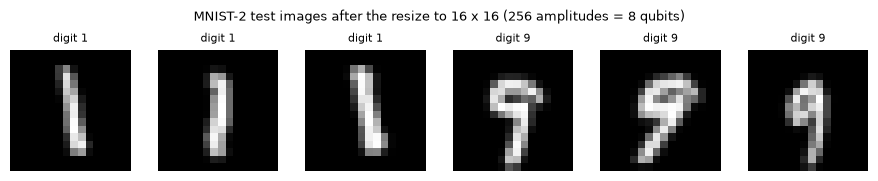

In [4]:
# ---------- Iris ----------
iris = load_iris()
Xi, yi = iris.data, iris.target
keep = yi != 1                                  # remove versicolor
Xi = Xi[keep][:, [0, 1, 2]]                     # remove the petal-width feature
yi = (yi[keep] == 2).astype(int)                # setosa -> 0, virginica -> 1
Xi = np.hstack([Xi, np.zeros((len(Xi), 1))])    # pad with a zero -> 4 amplitudes = 2 qubits
Xi = Xi / np.linalg.norm(Xi, axis=1, keepdims=True)
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, train_size=IRIS_N_TRAIN, test_size=IRIS_N_TEST,
                                              stratify=yi, random_state=SEED)
print("Iris:", Xi.shape, "train", Xi_tr.shape, np.bincount(yi_tr), "test", Xi_te.shape, np.bincount(yi_te))

# ---------- MNIST-2 ----------
def load_mnist_npz():
    path = MNIST_PATH or os.path.join(DATA_DIR, "mnist.npz")
    if not os.path.exists(path):
        urls = ["https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz",
                "https://s3.amazonaws.com/img-datasets/mnist.npz"]
        for u in urls:
            try:
                print("downloading", u)
                with urllib.request.urlopen(u, timeout=120) as r, open(path, "wb") as f:
                    f.write(r.read())
                break
            except Exception as e:
                print("  failed:", type(e).__name__, e)
        else:
            from sklearn.datasets import fetch_openml        # last resort (55 MB)
            mn = fetch_openml("mnist_784", version=1, as_frame=False, data_home=DATA_DIR)
            np.savez_compressed(path, x_train=mn.data[:60000].reshape(-1, 28, 28).astype(np.uint8),
                                y_train=mn.target[:60000].astype(np.uint8))
    d = np.load(path)
    return d["x_train"], d["y_train"]

from PIL import Image
xm, ym = load_mnist_npz()
sel = (ym == 1) | (ym == 9)
xm, ym = xm[sel], (ym[sel] == 9).astype(int)
resize16 = lambda im: np.asarray(Image.fromarray(im).resize((16, 16), Image.BILINEAR), float).ravel() / 255.0
Xm_raw = np.stack([resize16(im) for im in xm])                       # 16 x 16 pixels in [0, 1]
Xm = Xm_raw / np.linalg.norm(Xm_raw, axis=1, keepdims=True)           # amplitude vectors
perm = np.random.default_rng(SEED).permutation(len(Xm))
i_tr = perm[:MNIST_N_TRAIN]; i_va = perm[MNIST_N_TRAIN:MNIST_N_TRAIN + MNIST_N_VAL]
i_te = perm[MNIST_N_TRAIN + MNIST_N_VAL:MNIST_N_TRAIN + MNIST_N_VAL + MNIST_N_TEST]
Xm_tr, ym_tr = Xm[i_tr][:MNIST_TRAIN_USED], ym[i_tr][:MNIST_TRAIN_USED]
Xm_va, ym_va = Xm[i_va], ym[i_va]
Xm_te, ym_te = Xm[i_te], ym[i_te]
print("MNIST-2:", Xm.shape, "total", len(Xm), "| train used", len(Xm_tr), "| val", len(Xm_va), "| test", len(Xm_te),
      "| test class counts", np.bincount(ym_te))

fig, ax = plt.subplots(1, 6, figsize=(9, 1.8))
for a, k in zip(ax, list(np.where(ym_te == 0)[0][:3]) + list(np.where(ym_te == 1)[0][:3])):
    a.imshow(Xm_raw[i_te][k].reshape(16, 16), cmap="gray"); a.set_title("digit %d" % (1 if ym_te[k] == 0 else 9), fontsize=8); a.axis("off")
plt.suptitle("MNIST-2 test images after the resize to 16 x 16 (256 amplitudes = 8 qubits)", fontsize=9); plt.tight_layout(); plt.show()

## 2. The victim: a QNN classifier in PennyLane

The model of the paper's Figure 4 and Section 5.2.2: **amplitude encoding** of the (normalised) input onto `n` qubits,
**two `StronglyEntanglingLayers`** (each layer: one `Rot(phi, theta, omega)` on every qubit followed by a ring of CNOTs),
and a measurement of **one qubit**. The probability of outcome 1 of wire 0 is the score of class 1.

Parameters: `2 layers x n qubits x 3 angles` (12 for Iris, 48 for MNIST-2) plus one classical bias. The bias is our way to
reach the paper's "13 parameters" for Iris; it is added to the *measured* probability, so it works equally for simulated and
shot-based read-out (`# CHOICE`). Loss: mean-squared error between `P1 + bias` and the 0/1 label; Adam with the paper's
learning rate; mini-batches with the paper's sizes.

In [5]:
def make_qnode(n):
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev, interface="autograd", diff_method="backprop")
    def circuit(x, w):
        qml.AmplitudeEmbedding(x, wires=range(n), normalize=True)
        qml.StronglyEntanglingLayers(w, wires=range(n))
        return qml.probs(wires=0)
    return circuit

def train_qnn(circuit, n, Xtr, ytr, epochs, batch, seed, n_layers=N_LAYERS, lr=LEARNING_RATE, monitor=None):
    """Mini-batch Adam on the squared error of P1 + bias. Returns weights, bias, loss history (and monitor history)."""
    r = np.random.default_rng(seed)
    w = pnp.array(r.uniform(0, 2 * np.pi, (n_layers, n, 3)), requires_grad=True)   # CHOICE: uniform [0, 2 pi]
    b = pnp.array(0.0, requires_grad=True)
    opt = qml.AdamOptimizer(lr)
    hist, mon = [], []
    for ep in range(epochs):
        order = r.permutation(len(Xtr)); losses = []
        for s in range(0, len(Xtr), batch):
            j = order[s:s + batch]
            xb, yb = pnp.array(Xtr[j], requires_grad=False), pnp.array(ytr[j], requires_grad=False)
            (w, b), l = opt.step_and_cost(lambda w, b: pnp.mean((circuit(xb, w)[:, 1] + b - yb) ** 2), w, b)
            losses.append(float(l))
        hist.append(np.mean(losses))
        if monitor is not None:
            mon.append(monitor(w, b))
    return np.array(w), float(b), hist, mon

def p1_ideal(circuit, w, X):
    return np.array(circuit(X, w))[:, 1]

def accuracy_from_p1(p1, b, y):
    return float(((p1 + b > 0.5).astype(int) == y).mean())

circ2, circ8 = make_qnode(2), make_qnode(8)

# --- Iris: several seeds, the first one (SEED) is the victim used in all attacks
t0 = time.time()
iris_runs = []
for k in range(N_BASELINE_SEEDS):
    w_, b_, h_, _ = train_qnn(circ2, 2, Xi_tr, yi_tr, IRIS_EPOCHS, IRIS_BATCH, seed=SEED + k)
    iris_runs.append(dict(seed=SEED + k, w=w_, b=b_, loss=h_,
                          train_acc=accuracy_from_p1(p1_ideal(circ2, w_, Xi_tr), b_, yi_tr),
                          test_acc=accuracy_from_p1(p1_ideal(circ2, w_, Xi_te), b_, yi_te)))
print("Iris QNN trained %d times in %.0f s" % (N_BASELINE_SEEDS, time.time() - t0))
print(pd.DataFrame([{k: v for k, v in r_.items() if k not in ("w", "loss")} for r_ in iris_runs]).round(3).to_string(index=False))
w_iris, b_iris = iris_runs[0]["w"], iris_runs[0]["b"]
R["iris_test_acc_mean"] = float(np.mean([r_["test_acc"] for r_ in iris_runs]))
R["iris_test_acc_std"] = float(np.std([r_["test_acc"] for r_ in iris_runs]))
R["iris_test_acc_victim"] = iris_runs[0]["test_acc"]
print("Iris victim (seed %d): test accuracy %.3f | over seeds %.3f +- %.3f" % (SEED, R["iris_test_acc_victim"], R["iris_test_acc_mean"], R["iris_test_acc_std"]))

Iris QNN trained 5 times in 35 s
 seed      b  train_acc  test_acc
   42 -0.010        1.0       1.0
   43  0.016        1.0       1.0
   44 -0.002        1.0       1.0
   45 -0.002        1.0       1.0
   46 -0.007        1.0       1.0
Iris victim (seed 42): test accuracy 1.000 | over seeds 1.000 +- 0.000


MNIST-2 QNN: 50 epochs on 10152 images in 1441 s | validation acc 0.980 | test acc (254 images) 0.961


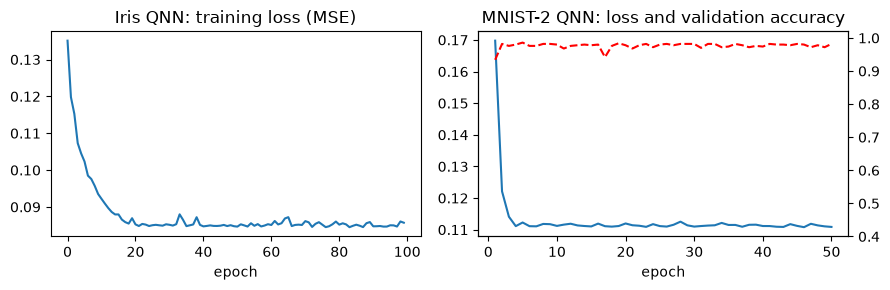

In [6]:
# --- MNIST-2 (8 qubits): one training run with the validation accuracy monitored after every epoch
def mnist_monitor(w, b):
    return accuracy_from_p1(p1_ideal(circ8, np.array(w), Xm_va[:500]), float(b), ym_va[:500])

t0 = time.time()
w_mnist, b_mnist, mnist_loss, mnist_val = train_qnn(circ8, 8, Xm_tr, ym_tr, MNIST_EPOCHS, MNIST_BATCH, seed=SEED, monitor=mnist_monitor)
R["mnist_test_acc"] = accuracy_from_p1(p1_ideal(circ8, w_mnist, Xm_te), b_mnist, ym_te)
R["mnist_val_acc"] = accuracy_from_p1(p1_ideal(circ8, w_mnist, Xm_va), b_mnist, ym_va)
print("MNIST-2 QNN: %d epochs on %d images in %.0f s | validation acc %.3f | test acc (254 images) %.3f"
      % (MNIST_EPOCHS, len(Xm_tr), time.time() - t0, R["mnist_val_acc"], R["mnist_test_acc"]))

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(iris_runs[0]["loss"]); ax[0].set_title("Iris QNN: training loss (MSE)"); ax[0].set_xlabel("epoch")
ax[1].plot(range(1, len(mnist_loss) + 1), mnist_loss, label="train loss"); ax[1].set_xlabel("epoch")
ax2 = ax[1].twinx(); ax2.plot(range(1, len(mnist_val) + 1), mnist_val, "r--", label="validation accuracy"); ax2.set_ylim(0.4, 1.02)
ax[1].set_title("MNIST-2 QNN: loss and validation accuracy"); plt.tight_layout(); plt.show()

### Classical baselines on exactly the same inputs

A random forest, an RBF-kernel SVM and a logistic regression are trained on the same normalised vectors that the QNN
receives (3 numbers + padding for Iris, 256 pixel values for MNIST-2). They give the reference for "loss of quantum
advantage" (one attack objective of the paper): once an attack pushes the QNN below the classical baseline, the quantum
model is no longer worth its cost.

In [7]:
def baselines(Xtr, ytr, Xte, yte, seed=SEED):
    out = {}
    for name, m in [("LogReg", LogisticRegression(max_iter=2000, random_state=seed)),
                    ("SVC rbf", SVC(kernel="rbf", C=1.0, gamma="scale", random_state=seed)),
                    ("RandomForest", RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=-1))]:
        t = time.time(); m.fit(Xtr, ytr); out[name] = (float((m.predict(Xte) == yte).mean()), time.time() - t)
    return out
bl_i = baselines(Xi_tr, yi_tr, Xi_te, yi_te)
bl_m = baselines(Xm_tr, ym_tr, Xm_te, ym_te)
tab = pd.DataFrame({"Iris test acc": {k: v[0] for k, v in bl_i.items()}, "MNIST-2 test acc": {k: v[0] for k, v in bl_m.items()}})
tab.loc["QNN (ideal simulator)"] = [R["iris_test_acc_victim"], R["mnist_test_acc"]]
R["baseline_iris"] = max(v[0] for v in bl_i.values()); R["baseline_mnist"] = max(v[0] for v in bl_m.values())
display(tab.round(3))
print("MNIST-2 baselines were trained on %d images (QNN: %d images, %d epochs)." % (len(Xm_tr), len(Xm_tr), MNIST_EPOCHS))

,Iris test acc,MNIST-2 test acc
LogReg,1.0,0.984
SVC rbf,1.0,0.996
RandomForest,1.0,1.000
QNN (ideal simulator),1.0,0.961


MNIST-2 baselines were trained on 10152 images (QNN: 10152 images, 50 epochs).


## 3. The same QNN in Qiskit, and Table 3

All hardware-style experiments need a Qiskit circuit that the transpiler can map onto IBM-like devices. The cell below
writes the PennyLane model gate by gate:

* amplitude encoding = `prepare_state` (Qiskit orders qubits little-endian, PennyLane big-endian, so the amplitude vector
  is bit-reversed);
* `StronglyEntanglingLayers` = for every layer `Rz(phi) Ry(theta) Rz(omega)` on each qubit, then CNOT(i -> (i + r) mod n)
  with range `r = (layer mod (n-1)) + 1`.

The check compares the Qiskit statevector with PennyLane's output probability for all test inputs. Then the circuit is
transpiled into a generic `{cx, u3}` gate set without optimisation (an architecture-independent depth, comparable to the
depth of 16 / 511 in the paper's Table 3).

In [8]:
def bitrev_perm(n):
    idx = np.arange(2 ** n); out = np.zeros_like(idx)
    for k in range(n):
        out |= ((idx >> k) & 1) << (n - 1 - k)
    return out

def qiskit_qnn(x, w, measure=True):
    """Qiskit version of the PennyLane QNN. Wire i of PennyLane = qubit i of Qiskit. Measures qubit 0 into clbit 0."""
    n_layers, n, _ = w.shape
    amps = np.asarray(x, float); amps = amps / np.linalg.norm(amps)
    qc = QuantumCircuit(n, 1 if measure else 0)
    qc.prepare_state(amps[bitrev_perm(n)], range(n))
    for l in range(n_layers):
        for i in range(n):
            qc.rz(w[l, i, 0], i); qc.ry(w[l, i, 1], i); qc.rz(w[l, i, 2], i)
        r = (l % (n - 1)) + 1
        for i in range(n):
            qc.cx(i, (i + r) % n)
    if measure:
        qc.measure(0, 0)
    return qc

def p1_qiskit(x, w):
    return Statevector(qiskit_qnn(x, w, measure=False)).probabilities([0])[1]

d_i = max(abs(p1_qiskit(x, w_iris) - p) for x, p in zip(Xi_te, p1_ideal(circ2, w_iris, Xi_te)))
d_m = max(abs(p1_qiskit(x, w_mnist) - p) for x, p in zip(Xm_te[:20], p1_ideal(circ8, w_mnist, Xm_te[:20])))
print("max |P1(Qiskit) - P1(PennyLane)|  Iris: %.1e   MNIST-2: %.1e" % (d_i, d_m))
assert d_i < 1e-8 and d_m < 1e-8, "the two implementations disagree"

def circuit_stats(qc):
    g = transpile(qc, basis_gates=["cx", "u3"], optimization_level=0)
    ops = g.count_ops()
    return dict(depth=g.depth(), one_qubit=ops.get("u3", 0), two_qubit=ops.get("cx", 0))
st_i = circuit_stats(qiskit_qnn(Xi_te[0], w_iris, measure=False))
st_m = circuit_stats(qiskit_qnn(Xm_te[0], w_mnist, measure=False))
ansatz_i = dict(one_qubit=N_LAYERS * 2 * 3, two_qubit=N_LAYERS * 2)
ansatz_m = dict(one_qubit=N_LAYERS * 8 * 3, two_qubit=N_LAYERS * 8)
t3 = pd.DataFrame({
    "Iris (paper)": dict(parameters=13, depth=16, single_qubit_gates=12, two_qubit_gates=4),
    "Iris (ansatz only, here)": dict(parameters=N_LAYERS * 2 * 3 + 1, depth="-", single_qubit_gates=ansatz_i["one_qubit"], two_qubit_gates=ansatz_i["two_qubit"]),
    "Iris (encoding + ansatz, {cx,u3})": dict(parameters=N_LAYERS * 2 * 3 + 1, depth=st_i["depth"], single_qubit_gates=st_i["one_qubit"], two_qubit_gates=st_i["two_qubit"]),
    "MNIST-2 (paper)": dict(parameters=961, depth=511, single_qubit_gates=960, two_qubit_gates=320),
    "MNIST-2 (ansatz only, here)": dict(parameters=N_LAYERS * 8 * 3 + 1, depth="-", single_qubit_gates=ansatz_m["one_qubit"], two_qubit_gates=ansatz_m["two_qubit"]),
    "MNIST-2 (encoding + ansatz, {cx,u3})": dict(parameters=N_LAYERS * 8 * 3 + 1, depth=st_m["depth"], single_qubit_gates=st_m["one_qubit"], two_qubit_gates=st_m["two_qubit"]),
}).T
display(t3)
R["depth_iris"], R["depth_mnist"] = st_i["depth"], st_m["depth"]
R["params_iris"] = N_LAYERS * 2 * 3 + 1

max |P1(Qiskit) - P1(PennyLane)|  Iris: 1.0e-15   MNIST-2: 5.8e-13


,parameters,depth,single_qubit_gates,two_qubit_gates
Iris (paper),13,16,12,4
"Iris (ansatz only, here)",13,-,12,4
"Iris (encoding + ansatz, {cx,u3})",13,13,15,5
MNIST-2 (paper),961,511,960,320
"MNIST-2 (ansatz only, here)",49,-,48,16
"MNIST-2 (encoding + ansatz, {cx,u3})",49,513,303,263


## 4. Crosstalk-induced fault injection (paper Section 5.2.1-5.2.2, Fig. 30, 32-35)

### 4.1 Building a simulated multi-tenant device

On a shared superconducting chip the victim QNN and an attacker's circuit run side by side. The attacker repeats CNOTs on
two qubits next to the victim; through the residual qubit-qubit coupling this disturbs the victim and, because all qubits
are measured at the end of the job, the victim also sits idle (and decoheres) while the long attacker circuit finishes.

The paper did this on real chips. Here the chip is **simulated**:

* **Device noise.** Gate errors (depolarizing + thermal relaxation), read-out errors and T1/T2 of the fake backend
  (`FakeNairobiV2`, `FakeBrisbane`; calibration snapshots shipped with `qiskit-ibm-runtime`) are turned into an Aer noise model
  restricted to the qubits that are used. Idle time of the victim is converted into a thermal-relaxation channel.
* **Scheduling.** Every gate gets the duration listed in the backend's properties; victim and attacker gates are placed
  on a common time line (as soon as possible, per qubit).
* **Crosstalk.** While an attacker two-qubit gate of duration `d` acts on qubit `a`, every victim qubit `v` that is *coupled
  to `a` in the device's coupling map* receives a `ZZ` rotation and a `ZX` rotation (the latter models drive spill-over)
  of angle `phi = 2 pi * zeta * d` (`zeta` = coupling rate). Qubits that are not neighbours feel nothing, which is why the
  "far" attacker of the paper (qubits 20, 21 on Brisbane) is harmless in the model. **`zeta` is an assumption** (the paper gives no
  value; it is a property of each chip): `ZETA_KHZ` in the configuration cell. Section 4.4 sweeps it, so the reader can see
  at which value the attack starts to work.

This is a *model* of the paper's experiment, not a measurement: whether a real chip has a given `zeta` cannot be checked here.

In [9]:
class DeviceNoise:
    """Gate/read-out noise of one fake backend, cached once, restricted to any set of physical qubits on demand."""
    def __init__(self, name, backend):
        self.name, self.backend = name, backend
        self.props = backend.properties()
        self.gate_errors = basic_device_gate_errors(self.props)
        self.two_q = "ecr" if "ecr" in backend.operation_names else "cx"
        self.edges = {tuple(sorted(e)) for e in backend.coupling_map.get_edges()}
        self.adj = {}
        for a, b in self.edges:
            self.adj.setdefault(a, set()).add(b); self.adj.setdefault(b, set()).add(a)
    def device(self, phys, extra=None, method="density_matrix"):
        if extra is not None:
            return SimDevice(self, phys, extra, method)
        key = (tuple(phys), method)
        if not hasattr(self, "_dev_cache"):
            self._dev_cache = {}
        if key not in self._dev_cache:
            self._dev_cache[key] = SimDevice(self, phys, None, method)
        return self._dev_cache[key]

class SimDevice:
    def __init__(self, dn, phys, extra=None, method="density_matrix"):
        self.dn, self.phys = dn, list(phys)
        self.qmap = {q: i for i, q in enumerate(self.phys)}
        nm = NoiseModel(basis_gates=["id", "rz", "sx", "x", "cx", "ecr", "rzz", "rzx"])
        for name, qubits, err in dn.gate_errors:
            if all(q in self.qmap for q in qubits):
                if extra is not None and name in ("sx", "x", dn.two_q):      # extra noise of "level p" (Fig. 36, 41): composed with the calibrated error
                    err = err.compose(extra if len(qubits) == 1 else extra.tensor(extra))
                nm.add_quantum_error(err, name, [self.qmap[q] for q in qubits])
        self.readout = {}
        for q in self.phys:
            p10 = dn.props.qubit_property(q, "prob_meas1_prep0")[0]; p01 = dn.props.qubit_property(q, "prob_meas0_prep1")[0]
            self.readout[q] = (p10, p01)
            nm.add_readout_error(ReadoutError([[1 - p10, p10], [p01, 1 - p01]]), [self.qmap[q]])
        self.noise_model = nm
        self.sim = AerSimulator(method=method, noise_model=nm)
    def compact(self, tq, drop_measure=True):
        """Re-index a transpiled (full-width) circuit onto the local qubits; returns circuit and measured local qubit."""
        qc = QuantumCircuit(len(self.phys), 0 if drop_measure else 1); mq = None     # mq: LOCAL index of the measured qubit
        for inst in tq.data:
            nm = inst.operation.name
            qs = [tq.find_bit(q).index for q in inst.qubits]
            if nm == "barrier":
                continue
            if nm == "measure":
                mq = self.qmap[qs[0]]
                if not drop_measure:
                    qc.measure(self.qmap[qs[0]], 0)
                continue
            qc.append(inst.operation, [self.qmap[q] for q in qs])
        return qc, mq
    def p_read1(self, p1_state, phys_q):
        """P(read 1) from P(state 1) with this qubit's assignment errors."""
        p10, p01 = self.readout[phys_q]
        return p1_state * (1 - p01) + (1 - p1_state) * p10

BACKENDS = {"Brisbane": FakeBrisbane, "Kyoto": FakeKyoto, "Osaka": FakeOsaka, "Nairobi": FakeNairobiV2}
_dn_cache = {}
def get_dn(name):
    if name not in _dn_cache:
        _dn_cache[name] = DeviceNoise(name, BACKENDS[name]())
    return _dn_cache[name]

def n_usable_couplers(name):
    """Number of couplers whose recorded two-qubit error in the calibration snapshot is below 2 %."""
    dn = get_dn(name); n = 0
    for a, b in dn.backend.coupling_map.get_edges():
        try:
            n += dn.props.gate_error(dn.two_q, [a, b]) < 0.02
        except Exception:
            pass
    return n

def good_layout(name):
    """CHOICE: physical qubits (0, 1) for the 2-qubit Iris QNN, unless the calibration snapshot marks that pair as unusable
    (coupler error above 2 % or read-out error above 5 %: the case for FakeKyoto, where the (0, 1) coupler has error 1.0);
    then the coupled pair with the smallest sum of coupler and read-out errors is used."""
    dn = get_dn(name); p = dn.props
    def cost(a, b):
        try:
            e2 = min(p.gate_error(dn.two_q, [a, b]) if (a, b) in [tuple(x) for x in dn.backend.coupling_map.get_edges()] else 9,
                     p.gate_error(dn.two_q, [b, a]) if (b, a) in [tuple(x) for x in dn.backend.coupling_map.get_edges()] else 9)
        except Exception:
            return 9
        return e2, max(p.readout_error(a), p.readout_error(b))
    c01 = cost(0, 1)
    if c01 != 9 and c01[0] < 0.02 and c01[1] < 0.05:
        return [0, 1]
    best = min(((sum(cost(a, b)) if cost(a, b) != 9 else 9), a, b) for a, b in dn.edges)
    return [best[1], best[2]]

def prepare(logical_qc, name, layout):
    """Transpile a logical circuit (with a final measure on qubit 0) to backend `name` with a fixed layout."""
    dn = get_dn(name)
    return transpile(logical_qc, dn.backend, initial_layout=layout, optimization_level=1, seed_transpiler=SEED)

def measured_phys(tq):
    for inst in tq.data:
        if inst.operation.name == "measure":
            return tq.find_bit(inst.qubits[0]).index

dn_b = get_dn("Brisbane"); dn_n = get_dn("Nairobi")
print("Brisbane: %d qubits, two-qubit gate %s | Nairobi: %d qubits, two-qubit gate %s" % (dn_b.backend.num_qubits, dn_b.two_q, dn_n.backend.num_qubits, dn_n.two_q))
print("coupled? Brisbane (1,2):", (1, 2) in dn_b.edges, "(2,3):", (2, 3) in dn_b.edges, "(20,21):", (20, 21) in dn_b.edges,
      "| Nairobi (1,3):", (1, 3) in dn_n.edges, "(3,5):", (3, 5) in dn_n.edges, "(5,6):", (5, 6) in dn_n.edges)

for nm_, qs_ in [("Nairobi", [0, 1, 3]), ("Brisbane", [0, 1, 2, 3])]:
    d_ = get_dn(nm_)
    print(nm_, "calibration snapshot, qubit: (T1, T2) in us:", {q: (round(d_.props.t1(q) * 1e6), round(d_.props.t2(q) * 1e6)) for q in qs_})
# the paper's own back-of-the-envelope check (caption of Fig. 32): T2 = 127.37 us, median gate time 660 ns
R["gates_before_decoherence"] = int(127.37e-6 / 660e-9)
print("gates that fit into T2 = 127.37 us at 660 ns per gate:", R["gates_before_decoherence"], "(paper: 192)")

Brisbane: 127 qubits, two-qubit gate ecr | Nairobi: 7 qubits, two-qubit gate cx
coupled? Brisbane (1,2): True (2,3): True (20,21): True | Nairobi (1,3): True (3,5): True (5,6): True
Nairobi calibration snapshot, qubit: (T1, T2) in us: {0: (89, 16), 1: (87, 126), 3: (75, 76)}
Brisbane calibration snapshot, qubit: (T1, T2) in us: {0: (237, 49), 1: (158, 242), 2: (226, 246), 3: (394, 386)}
gates that fit into T2 = 127.37 us at 660 ns per gate: 192 (paper: 192)


In [10]:
def gate_duration(dn, name, qs):
    if name in ("rz", "id", "barrier", "measure", "delay") or name.startswith("save"):
        return 0.0
    try:
        return dn.props.gate_length(name, qs)
    except Exception:
        return 0.0

def build_attacked(dn, dev, victim_tq, attacker_tq, zeta_hz, idle_relax=True, sign_seed=SEED):
    """Schedule victim and attacker on one time line, add ZZ/ZX crosstalk during attacker 2-qubit gates and idle relaxation
    of the victim; returns a compact circuit (no measurement) and the total duration in seconds.
    victim_tq / attacker_tq are transpiled (full-width) circuits; attacker_tq may be None (no attacker)."""
    vict_q = sorted({victim_tq.find_bit(q).index for inst in victim_tq.data for q in inst.qubits})
    ops = []
    def sched(circ, tag):
        t_av = {}
        for inst in circ.data:
            qs = [circ.find_bit(q).index for q in inst.qubits]; nm = inst.operation.name
            if nm in ("barrier", "measure"):
                continue
            d = gate_duration(dn, nm, qs)
            st = max([t_av.get(q, 0.0) for q in qs] + [0.0]); en = st + d
            for q in qs:
                t_av[q] = en
            ops.append((st, 0 if tag == "v" else 1, tag, inst.operation, qs, d))
        return t_av
    tv = sched(victim_tq, "v")
    ta = sched(attacker_tq, "a") if attacker_tq is not None else {}
    t_end = max(list(tv.values()) + list(ta.values()))
    events = []
    sg = np.random.default_rng(sign_seed)      # CHOICE: sign of the ZX spill-over is random per attacker gate (uncontrolled pulse phase)
    if attacker_tq is not None and zeta_hz > 0:
        for (st, _, tag, op, qs, d) in ops:
            if tag == "a" and len(qs) == 2:
                phi = 2 * np.pi * zeta_hz * d
                for a in qs:
                    for v in vict_q:
                        if v in dn.adj.get(a, ()) and v not in qs:
                            events.append((st + d / 2, 1, "x", (phi, phi * sg.choice([-1.0, 1.0])), [a, v], 0.0))
    allops = sorted(ops + events, key=lambda r: (r[0], r[1]))
    qc = QuantumCircuit(len(dev.phys)); last = {q: 0.0 for q in vict_q}
    def idle(q, gap):
        if gap > 1e-12:
            t1 = dn.props.t1(q); t2 = min(dn.props.t2(q), 2 * t1)
            qc.append(thermal_relaxation_error(t1, t2, gap).to_instruction(), [dev.qmap[q]])
    for (st, _, tag, op, qs, d) in allops:
        if tag == "x":
            qc.rzz(op[0], dev.qmap[qs[0]], dev.qmap[qs[1]])
            qc.rzx(op[1], dev.qmap[qs[0]], dev.qmap[qs[1]])
            continue
        if tag == "v" and idle_relax:
            for q in qs:
                idle(q, st - last[q])
        qc.append(op, [dev.qmap[q] for q in qs])
        if tag == "v":
            for q in qs:
                last[q] = st + d
    if idle_relax and attacker_tq is not None:
        for q in vict_q:
            idle(q, t_end - last[q])
    return qc, t_end

def attacker_circuit(dn, pair, k_cx):
    """H then k_cx CNOTs on a coupled pair, transpiled WITHOUT optimisation (so CNOT pairs are not cancelled)."""
    c = QuantumCircuit(2); c.h(0)
    for _ in range(k_cx):
        c.cx(0, 1)
    return transpile(c, dn.backend, initial_layout=list(pair), optimization_level=0, seed_transpiler=SEED)

_vq_cache, _aq_cache = {}, {}
def victim_probability(dn, x, w, layout, pair, k_cx, zeta_khz, idle_relax=True, exact=True, shots=SHOTS, seed=0, sign_seed=SEED):
    """P(read 1) on the measured qubit of the victim, with (pair is not None) or without an attacker (cached transpilation)."""
    key = (dn.name, x.tobytes(), w.tobytes(), tuple(layout))
    if key not in _vq_cache:
        vq = prepare(qiskit_qnn(x, w), dn.name, layout); _vq_cache[key] = (vq, measured_phys(vq))
    vq, mphys = _vq_cache[key]
    phys = sorted(set(layout) | (set(pair) if pair is not None else set()))
    dev = dn.device(phys)
    aq = None
    if pair is not None:
        ak = (dn.name, tuple(pair), k_cx)
        if ak not in _aq_cache:
            _aq_cache[ak] = attacker_circuit(dn, pair, k_cx)
        aq = _aq_cache[ak]
    qc, t_end = build_attacked(dn, dev, vq, aq, zeta_khz * 1e3, idle_relax, sign_seed=sign_seed)
    if exact:
        qc.save_probabilities([dev.qmap[mphys]])
        p1 = dev.sim.run(qc).result().data(0)["probabilities"][1]
        return dev.p_read1(p1, mphys)
    qc.add_register(ClassicalRegister(1)); qc.measure(dev.qmap[mphys], 0)
    counts = dev.sim.run(qc, shots=shots, seed_simulator=seed).result().get_counts()
    return counts.get("1", 0) / shots

### 4.2 Reproducing Figure 34: one input, normal vs attacked (Nairobi-like and Brisbane-like device)

Setting of the paper's Fig. 32-34: the victim QNN (Iris) on two qubits, the attacker next to it ("near") or far away, the
class confidence of **one test input** averaged over 10 runs of 8000 shots. Here the "normal" bar is the victim alone, the
"near" bar has the attacker on a pair of qubits coupled to the readout qubit, the "far" bar has the attacker on a pair that
is not connected to the victim. The "idle only" bar is a control: the same long attacker circuit but with `zeta = 0`, i.e. only
the extra waiting time (decoherence) without any crosstalk, the effect the paper dismisses with its 192-versus-35-gates
argument.

Qubit placement (`# CHOICE`): wire 0, the readout qubit, sits on physical qubit 1; wire 1 on qubit 0. Near attacker: qubits (2, 3)
on Brisbane (as in the paper) and (3, 5) on Nairobi (the pair next to qubit 1 that is a real coupling in the H-shaped Falcon);
far attacker: (20, 21) and (5, 6).

sample test input index 2 | ideal P(class 1) = 0.709


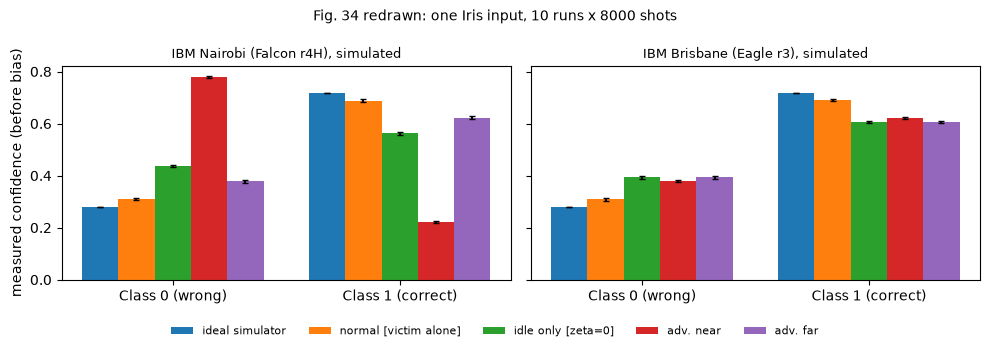

,device,scenario,conf_class0,conf_class1,std
0,Nairobi,ideal simulator,0.281,0.719,0.000
1,Nairobi,normal [victim alone],0.311,0.689,0.004
2,Nairobi,idle only [zeta=0],0.437,0.563,0.005
3,Nairobi,adv. near,0.778,0.222,0.004
4,Nairobi,adv. far,0.378,0.622,0.005
5,Brisbane,ideal simulator,0.281,0.719,0.000
6,Brisbane,normal [victim alone],0.309,0.691,0.005
7,Brisbane,idle only [zeta=0],0.394,0.606,0.006
8,Brisbane,adv. near,0.378,0.622,0.004
9,Brisbane,adv. far,0.394,0.606,0.006


In [11]:
SETUP = {"Nairobi":  dict(layout=[1, 0], near=(3, 5),  far=(5, 6),   label="IBM Nairobi (Falcon r4H), simulated"),
         "Brisbane": dict(layout=[1, 0], near=(2, 3),  far=(20, 21), label="IBM Brisbane (Eagle r3), simulated")}
# sample: first class-1 test flower (class 1 is the "correct class" in the paper's description)
k_sample = int(np.where(yi_te == 1)[0][0]); x_s = Xi_te[k_sample]
print("sample test input index", k_sample, "| ideal P(class 1) = %.3f" % (p1_ideal(circ2, w_iris, x_s[None])[0] + b_iris))

rows = []
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, dname in zip(axes, ["Nairobi", "Brisbane"]):
    dn = get_dn(dname); cfg = SETUP[dname]; z = ZETA_KHZ[dname]
    scen = {"ideal simulator": None, "normal [victim alone]": (None, z), "idle only [zeta=0]": (cfg["near"], 0.0),
            "adv. near": (cfg["near"], z), "adv. far": (cfg["far"], z)}
    res = {}
    for name, spec in scen.items():
        if spec is None:
            p1 = p1_ideal(circ2, w_iris, x_s[None])[0]; res[name] = (1 - p1, p1, 0.0, 0.0); continue
        pair, zz = spec
        ps = np.array([victim_probability(dn, x_s, w_iris, cfg["layout"], pair, K_CX, zz, exact=False, shots=SHOTS, seed=SEED + r)
                       for r in range(N_XT_RUNS)])
        res[name] = (1 - ps.mean(), ps.mean(), ps.std(), ps.std())
    names = list(res); xs = np.arange(2); wd = 0.16
    for i, nme in enumerate(names):
        ax.bar(xs + (i - 2) * wd, [res[nme][0], res[nme][1]], wd, yerr=[res[nme][2], res[nme][3]], label=nme, capsize=2)
    ax.set_xticks(xs); ax.set_xticklabels(["Class 0 (wrong)", "Class 1 (correct)"]); ax.set_title(cfg["label"], fontsize=9)
    ax.set_ylabel("measured confidence (before bias)" if dname == "Nairobi" else "")
    for nme in names:
        rows.append(dict(device=dname, scenario=nme, conf_class0=res[nme][0], conf_class1=res[nme][1], std=res[nme][2]))
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=5, fontsize=8, frameon=False)
plt.suptitle("Fig. 34 redrawn: one Iris input, %d runs x %d shots" % (N_XT_RUNS, SHOTS), fontsize=10)
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()
fig34 = pd.DataFrame(rows); display(fig34.round(3))

### 4.3 Does the attack work? The whole test set, three scenarios per device

One input is an anecdote. The cell below runs all 40 Iris test flowers through each scenario (exact probabilities including
read-out errors, class = `P1 + bias > 0.5`) and reports the test accuracy and the mean confidence in the true class.
The **crosstalk effect** is the mean absolute change of `P1` between the attacked run and the "idle only" control, i.e.
what the coupling adds on top of the extra waiting time.

In [12]:
def scenario_table(dname, zeta_khz, k_cx=K_CX, layout=None):
    cfg = SETUP[dname]; dn = get_dn(dname); layout = layout or cfg["layout"]
    scen = {"normal [victim alone]": (None, 0.0), "idle only [near, zeta=0]": (cfg["near"], 0.0), "adv. near": (cfg["near"], zeta_khz),
            "idle only [far, zeta=0]": (cfg["far"], 0.0), "adv. far": (cfg["far"], zeta_khz)}
    P = {nm: np.array([victim_probability(dn, x, w_iris, layout, pr, k_cx, z) for x in Xi_te]) for nm, (pr, z) in scen.items()}
    ctrl = {"adv. near": "idle only [near, zeta=0]", "adv. far": "idle only [far, zeta=0]"}   # same pair, same duration, no coupling
    out = []
    for nm, p in P.items():
        out.append(dict(device=dname, scenario=nm, accuracy=float(((p + b_iris > 0.5) == yi_te).mean()),
                        mean_conf_true_class=float(np.mean(np.where(yi_te == 1, p, 1 - p))),
                        crosstalk_effect=float(np.mean(np.abs(p - P[ctrl[nm]]))) if nm in ctrl else np.nan))
    return pd.DataFrame(out), P

tabs = {}
for dname in ["Nairobi", "Brisbane"]:
    tabs[dname], _ = scenario_table(dname, ZETA_KHZ[dname])
t43 = pd.concat(tabs.values(), ignore_index=True)
display(t43.round(3))
R["xt"] = t43
# the same on Brisbane when the attacker sits next to the *other* victim qubit (wire 1 on physical qubit 1, readout qubit 0 far from it)
alt, _ = scenario_table("Brisbane", ZETA_KHZ["Brisbane"] * 10, layout=[0, 1])
print("sensitivity: readout qubit NOT next to the attacker (layout [0, 1]), Brisbane with a 10x stronger coupling:")
display(alt.round(3))

,device,scenario,accuracy,mean_conf_true_class,crosstalk_effect
0,Nairobi,normal [victim alone],1.0,0.701,NaN
1,Nairobi,"idle only [near, zeta=0]",1.0,0.664,NaN
2,Nairobi,adv. near,0.5,0.394,0.270
3,Nairobi,"idle only [far, zeta=0]",1.0,0.682,NaN
4,Nairobi,adv. far,1.0,0.682,0.000
5,Brisbane,normal [victim alone],1.0,0.699,NaN
6,Brisbane,"idle only [near, zeta=0]",1.0,0.674,NaN
7,Brisbane,adv. near,1.0,0.673,0.017
8,Brisbane,"idle only [far, zeta=0]",1.0,0.674,NaN
9,Brisbane,adv. far,1.0,0.674,0.000


sensitivity: readout qubit NOT next to the attacker (layout [0, 1]), Brisbane with a 10x stronger coupling:


,device,scenario,accuracy,mean_conf_true_class,crosstalk_effect
0,Brisbane,normal [victim alone],1.000,0.698,NaN
1,Brisbane,"idle only [near, zeta=0]",1.000,0.681,NaN
2,Brisbane,adv. near,0.975,0.664,0.08
3,Brisbane,"idle only [far, zeta=0]",1.000,0.681,NaN
4,Brisbane,adv. far,1.000,0.681,0.00


### 4.4 How strong must the coupling be? Sweeps over `zeta` and over the length of the attacker circuit

The paper concludes that crosstalk is "too weak" on Eagle r3 chips but that "the threat is not completely ruled out" for other
devices. The two sweeps make that statement quantitative in the model: the left panel varies the coupling rate (attacker next to the
readout qubit, `K_CX` CNOTs), the right panel varies the number of CNOTs in the drive for the Nairobi-like device. The literature
quoted in Section 5.2.1 (Deshpande et al.) saw an effect only for more than about five repetitions.

sweeps (40 test inputs, 3 sign realisations) took 405 s


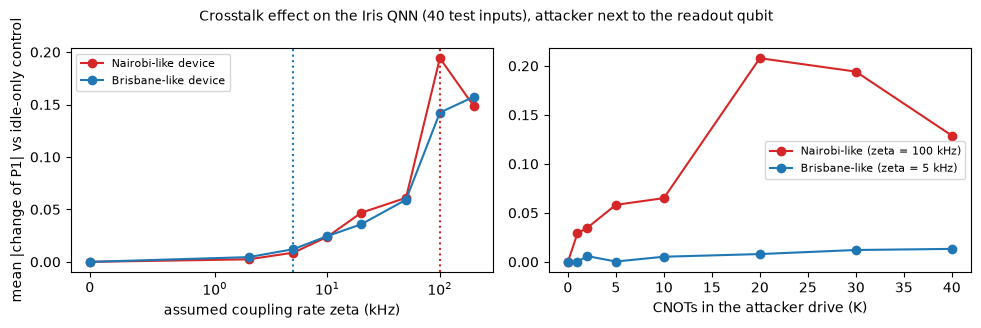

mean |change of P1| against the zeta = 0 control, sweep over zeta (kHz)


value,0,2,5,10,20,50,100,200
device,,,,,,,,
Brisbane,0.0,0.005,0.012,0.025,0.036,0.059,0.142,0.157
Nairobi,0.0,0.002,0.009,0.024,0.047,0.061,0.194,0.148


mean |change of P1| against the zeta = 0 control, sweep over K (CNOTs in the drive)


value,0,1,2,5,10,20,30,40
device,,,,,,,,
Brisbane,0.0,0.000,0.006,0.000,0.005,0.008,0.012,0.013
Nairobi,0.0,0.029,0.035,0.058,0.065,0.208,0.194,0.129


In [13]:
ZETAS = [0, 5, 20, 50, 100, 200] if FAST_MODE else [0, 2, 5, 10, 20, 50, 100, 200]
KS = [0, 2, 5, 10, 30] if FAST_MODE else [0, 1, 2, 5, 10, 20, 30, 40]
N_SIGN = 1 if FAST_MODE else 3      # random-sign realisations of the ZX spill-over that are averaged in the sweeps
sw_idx = np.concatenate([np.where(yi_te == 0)[0][:10], np.where(yi_te == 1)[0][:10]]) if FAST_MODE else np.arange(len(yi_te))
Xs, ys = Xi_te[sw_idx], yi_te[sw_idx]
_ctrl = {}
def xt_point(dn, cfg, zeta, k):
    """mean accuracy and mean |change of P1| w.r.t. the zeta = 0 control (same pair, same K), averaged over N_SIGN sign realisations."""
    ck = (dn.name, k)
    if ck not in _ctrl:
        _ctrl[ck] = np.array([victim_probability(dn, x, w_iris, cfg["layout"], cfg["near"], k, 0.0) for x in Xs])
    accs, effs = [], []
    for sd in range(N_SIGN):
        p = np.array([victim_probability(dn, x, w_iris, cfg["layout"], cfg["near"], k, zeta, sign_seed=SEED + sd) for x in Xs])
        accs.append(((p + b_iris > 0.5) == ys).mean()); effs.append(np.mean(np.abs(p - _ctrl[ck])))
    return float(np.mean(accs)), float(np.mean(effs))
rows = []
t0 = time.time()
for dname in ["Nairobi", "Brisbane"]:
    dn = get_dn(dname); cfg = SETUP[dname]
    for z in ZETAS:
        if z == 0:
            rows.append(dict(device=dname, sweep="zeta", value=0, accuracy=np.nan, effect=0.0)); continue
        a, e = xt_point(dn, cfg, z, K_CX); rows.append(dict(device=dname, sweep="zeta", value=z, accuracy=a, effect=e))
    for k in KS:
        if k == 0:
            rows.append(dict(device=dname, sweep="K", value=0, accuracy=np.nan, effect=0.0))
        else:
            a, e = xt_point(dn, cfg, ZETA_KHZ[dname], k); rows.append(dict(device=dname, sweep="K", value=k, accuracy=a, effect=e))
sw = pd.DataFrame(rows); print("sweeps (%d test inputs, %d sign realisations) took %.0f s" % (len(Xs), N_SIGN, time.time() - t0))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
for dname, c in [("Nairobi", "C3"), ("Brisbane", "C0")]:
    s = sw[(sw.device == dname) & (sw.sweep == "zeta")]
    ax[0].plot(s.value, s.effect, "o-", color=c, label=dname + "-like device")
    s = sw[(sw.device == dname) & (sw.sweep == "K")]
    ax[1].plot(s.value, s.effect, "o-", color=c, label=dname + "-like (zeta = %g kHz)" % ZETA_KHZ[dname])
ax[0].set_xscale("symlog", linthresh=1); ax[0].set_xlabel("assumed coupling rate zeta (kHz)"); ax[0].set_ylabel("mean |change of P1| vs idle-only control")
ax[0].axvline(ZETA_KHZ["Brisbane"], color="C0", ls=":"); ax[0].axvline(ZETA_KHZ["Nairobi"], color="C3", ls=":"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("CNOTs in the attacker drive (K)"); ax[1].legend(fontsize=8)
plt.suptitle("Crosstalk effect on the Iris QNN (40 test inputs), attacker next to the readout qubit", fontsize=10); plt.tight_layout(); plt.show()
for sweep_name in ["zeta", "K"]:
    print("mean |change of P1| against the zeta = 0 control, sweep over", "zeta (kHz)" if sweep_name == "zeta" else "K (CNOTs in the drive)")
    display(sw[sw.sweep == sweep_name].pivot_table(index="device", columns="value", values="effect").round(3))
R["xt_sweep"] = sw

### 4.5 MNIST-2 under crosstalk (paper Fig. 35)

The 8-qubit MNIST-2 QNN has a circuit about 500 gates deep (Table 3), far beyond what a Brisbane-class device keeps coherent. The
paper reports that the confidence is *random with and without the attack*. The cell below transpiles the 8-qubit circuit onto
Brisbane qubits (7 ... 0 for wires 0 ... 7), adds the attacker on the neighbouring qubits (8, 9) and compares the class confidences.
(A 10-qubit density matrix is the largest object simulated here, hence only a few test images.)

MNIST-2 crosstalk: 8 images, 89 s


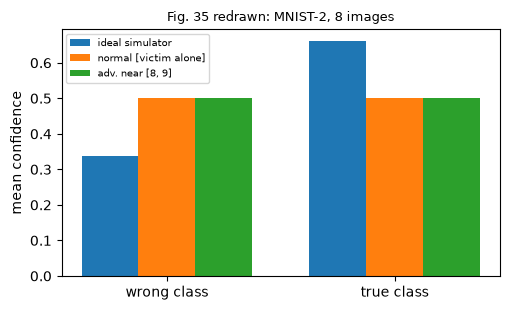

accuracy on these images: {'ideal simulator': 1.0, 'normal [victim alone]': 0.5, 'adv. near [8, 9]': 0.5}
mean |P1 - 0.5| (0 = pure noise): {'ideal simulator': 0.161, 'normal [victim alone]': 0.011, 'adv. near [8, 9]': 0.011}


In [14]:
def mnist_victim_tq(dname, x, layout):
    return prepare(qiskit_qnn(x, w_mnist), dname, layout)

dn = get_dn("Brisbane")
layout8 = list(range(7, -1, -1))        # wire 0 on physical qubit 7, which touches the attacker qubit 8
pair8 = (8, 9)
sel_idx = np.concatenate([np.where(ym_te == 0)[0][:MNIST_XT_N], np.where(ym_te == 1)[0][:MNIST_XT_N]])
t0 = time.time(); res35 = {"ideal simulator": [], "normal [victim alone]": [], "adv. near [8, 9]": []}
for k in sel_idx:
    x = Xm_te[k]
    res35["ideal simulator"].append(p1_ideal(circ8, w_mnist, x[None])[0])
    vq = mnist_victim_tq("Brisbane", x, layout8); mq = measured_phys(vq)
    used = sorted({vq.find_bit(q).index for inst in vq.data for q in inst.qubits})
    for nm, pr in [("normal [victim alone]", None), ("adv. near [8, 9]", pair8)]:
        dev = dn.device(sorted(set(used) | (set(pr) if pr else set())))
        aq = attacker_circuit(dn, pr, K_CX) if pr else None
        qc, _ = build_attacked(dn, dev, vq, aq, ZETA_KHZ["Brisbane"] * 1e3)
        qc.save_probabilities([dev.qmap[mq]])
        res35[nm].append(dev.p_read1(dev.sim.run(qc).result().data(0)["probabilities"][1], mq))
print("MNIST-2 crosstalk: %d images, %.0f s" % (len(sel_idx), time.time() - t0))
fig, ax = plt.subplots(figsize=(5.2, 3.2)); wd = 0.25
for i, (nm, v) in enumerate(res35.items()):
    v = np.array(v); y = ym_te[sel_idx]
    ax.bar(np.arange(2) + (i - 1) * wd, [np.mean(np.where(y == 1, 1 - v, v)), np.mean(np.where(y == 1, v, 1 - v))], wd, label=nm)
ax.set_xticks([0, 1]); ax.set_xticklabels(["wrong class", "true class"]); ax.set_ylabel("mean confidence"); ax.legend(fontsize=7)
ax.set_title("Fig. 35 redrawn: MNIST-2, %d images" % len(sel_idx), fontsize=9); plt.tight_layout(); plt.show()
acc35 = {nm: float(np.mean(((np.array(v) + b_mnist) > 0.5).astype(int) == ym_te[sel_idx])) for nm, v in res35.items()}
conf35 = {nm: float(np.mean(np.abs(np.array(v) - 0.5))) for nm, v in res35.items()}
print("accuracy on these images:", {k: round(v, 3) for k, v in acc35.items()})
print("mean |P1 - 0.5| (0 = pure noise):", {k: round(v, 3) for k, v in conf35.items()})
R["mnist_xt_acc"] = acc35; R["mnist_xt_conf"] = conf35

## 5. Noise amplification by falsified calibration data (paper Section 5.2.2, Fig. 36)

If an attacker can lie about the device calibration, the transpiler picks worse qubits and the circuit runs under more noise.
The paper measures how sensitive the Iris QNN is to noise by adding noise of increasing *level* (0 ... 0.5) to simulated
Brisbane, Kyoto and Osaka (all Eagle r3) and plots the test accuracy for four channels: depolarizing, amplitude damping, phase damping, and
amplitude + phase damping.

Here, "level `p`" is an extra single-qubit channel of strength `p` after every physical `sx`, `x` and `ecr` gate (on each
qubit the gate touches; `rz` is a virtual gate and stays free) on top of the backend's own noise (`# CHOICE`, the paper
does not define it). The circuit is transpiled once per test input; read-out errors and 8000 binomial shots are included.

**Kyoto caveat.** The calibration snapshot of `FakeKyoto` shipped with `qiskit-ibm-runtime` records an error of exactly 1.0 for
*every* `ecr` coupler, so no two-qubit circuit can run on it: the QNN would be a coin flip even without any attack. The cell therefore
skips every backend without a coupler below 2 % error (this removes Kyoto, in full mode, from Fig. 36 and Fig. 45); Brisbane and Osaka
are used. The Iris QNN sits on physical qubits (0, 1) of each backend (`good_layout`).

Brisbane: 125 couplers with recorded two-qubit error < 2% in the calibration snapshot


Kyoto: 0 couplers with recorded two-qubit error < 2% in the calibration snapshot
  -> Kyoto is skipped: its shipped calibration snapshot has no usable two-qubit gate


Osaka: 124 couplers with recorded two-qubit error < 2% in the calibration snapshot
  Brisbane: Iris QNN on physical qubits [0, 1]


  Osaka: Iris QNN on physical qubits [0, 1]


noise sweeps took 33 s


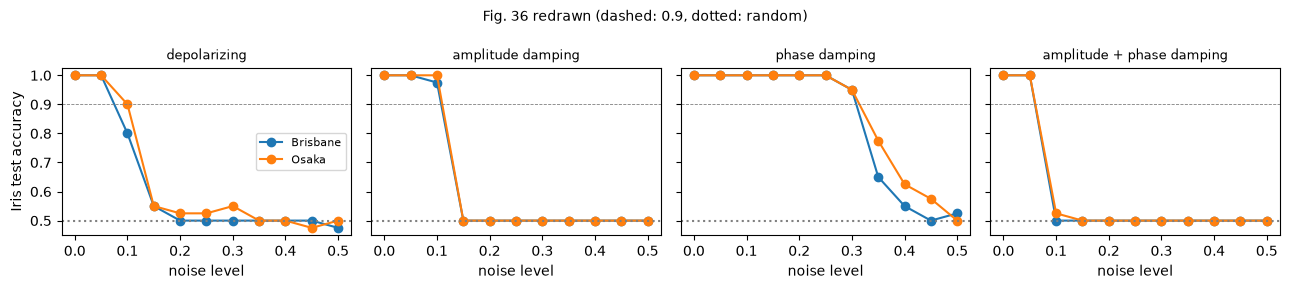

Brisbane                                                                  Osaka                                                          
     depolarizing amplitude damping phase damping amplitude + phase damping depolarizing amplitude damping phase damping amplitude + phase damping
0.00        1.000             1.000         1.000                       1.0        1.000               1.0         1.000                     1.000
0.05        1.000             1.000         1.000                       1.0        1.000               1.0         1.000                     1.000
0.10        0.800             0.975         1.000                       0.5        0.900               1.0         1.000                     0.525
0.15        0.550             0.500         1.000                       0.5        0.550               0.5         1.000                     0.500
0.20        0.500             0.500         1.000                       0.5        0.525               0.5         1.000                     0.500
0.25        0.500             0.500         1.000                       0.5        0.525               0.5         1.000                     0.500
0.30        0.500             0.500         0.950                       0.5        0.550               0.5         0.950                     0.500
0.35        0.500             0.500         0.650                       0.5        0.500               0.5         0.775                     0.500
0.40        0.500             0.500         0.550                       0.5        0.500               0.5         0.625                     0.500
0.45        0.500             0.500         0.500                       0.5        0.475               0.5         0.575                     0.500
0.50        0.475             0.500         0.525                       0.5        0.500               0.5         0.500                     0.500

In [15]:
def extra_error(kind, p):
    if p == 0:
        return None
    if kind == "depolarizing":
        return depolarizing_error(p, 1)
    if kind == "amplitude damping":
        return amplitude_damping_error(p)
    if kind == "phase damping":
        return phase_damping_error(p)
    if kind == "amplitude + phase damping":
        return amplitude_damping_error(p).compose(phase_damping_error(p))
KINDS = ["depolarizing", "amplitude damping", "phase damping", "amplitude + phase damping"]
rs_sweep = np.random.default_rng(SEED + 5)

def sweep_backend(name):
    layout = good_layout(name); print("  %s: Iris QNN on physical qubits %s" % (name, layout))
    dn = get_dn(name); tqs = [prepare(qiskit_qnn(x, w_iris), name, list(layout)) for x in Xi_te]
    mp = measured_phys(tqs[0]); out = {}
    for kind in KINDS:
        accs = []
        for p in NOISE_LEVELS:
            dev = dn.device(sorted(layout), extra=extra_error(kind, p))
            circs = []
            for tq in tqs:
                c, mq = dev.compact(tq); c.save_probabilities([mq]); circs.append(c)
            res = dev.sim.run(circs).result()
            P1 = np.array([dev.p_read1(res.data(i)["probabilities"][1], mp) for i in range(len(circs))])
            k = rs_sweep.binomial(SHOTS, P1) / SHOTS
            accs.append(float(((k + b_iris > 0.5).astype(int) == yi_te).mean()))
        out[kind] = accs
    return out

for name in list(SWEEP_BACKENDS):
    nu = n_usable_couplers(name)
    print("%s: %d couplers with recorded two-qubit error < 2%% in the calibration snapshot" % (name, nu))
    if nu == 0:     # FakeKyoto: every ecr entry has error 1.0, so ANY two-qubit circuit is pure noise on it; not a result about attacks
        print("  -> %s is skipped: its shipped calibration snapshot has no usable two-qubit gate" % name)
        SWEEP_BACKENDS.remove(name)
t0 = time.time()
sweep36 = {name: sweep_backend(name) for name in SWEEP_BACKENDS}
print("noise sweeps took %.0f s" % (time.time() - t0))
fig, ax = plt.subplots(1, 4, figsize=(13, 2.9), sharey=True)
for a, kind in zip(ax, KINDS):
    for name in SWEEP_BACKENDS:
        a.plot(NOISE_LEVELS, sweep36[name][kind], "o-", label=name)
    a.set_title(kind, fontsize=9); a.set_xlabel("noise level"); a.axhline(0.5, color="gray", ls=":"); a.axhline(0.9, color="gray", ls="--", lw=0.6)
ax[0].set_ylabel("Iris test accuracy"); ax[0].legend(fontsize=8); plt.suptitle("Fig. 36 redrawn (dashed: 0.9, dotted: random)", fontsize=10)
plt.tight_layout(); plt.show()
df36 = pd.concat({n: pd.DataFrame(v, index=NOISE_LEVELS) for n, v in sweep36.items()}, axis=1)
display(df36.round(3))
R["sweep36"] = sweep36

## 6. Transpiler gate injection and the parity-check defence (paper Sections 6.1.2 and 6.2.2, Fig. 41-44)

A malicious or compromised transpiler (or configuration file) can add gates that **change nothing mathematically**: a pair
`Rx(pi/2 + eps), Rx(-pi/2)` with `eps` about 1e-5 is, up to a 1e-5 rotation, the identity, so an equivalence checker that compares
the unitaries of the submitted and the transpiled circuit sees no difference. On hardware each real gate (`sx`, `x`, `ecr`)
costs noise, so hundreds of such pairs pull the output towards a random result. `Rz` is a *virtual* gate on IBM hardware (a
phase shift of the following pulses), carries no error and is therefore harmless: a falsifiable prediction of the paper.

**How it is simulated here, exactly and cheaply.** The injected gates act on the measured qubit only, after the QNN. So
(1) the QNN is simulated once per input, giving the reduced 2 x 2 density matrix of the measured qubit;
(2) one injected block (transpiled to `rz, sx, x` without optimisation, with the backend's noise on that qubit) is turned into a
4 x 4 superoperator `S` by Aer's `superop` method; (3) `S^N` is applied to the density matrix. The first cell checks this
shortcut against a brute-force simulation of the full circuit with the gates appended.

**Which noise acts on the injected gates (`# CHOICE`).** The paper does not say. The 8-qubit MNIST-2 circuit is already a coin flip
on a noisy Brisbane model (sections 4.5 and 7.1), so an injection effect can only be seen on MNIST-2 if the QNN itself ran cleanly;
the QNN is therefore taken noise-free here and **only the injected gates are noisy**. Three noise levels for the injected gates:
the calibrated Brisbane `sx` / `x` errors as they are (a few 1e-4 per gate), and the same plus an extra depolarizing error of
3e-3 or 1e-2 per gate (older or noisier hardware, or an attacker who chooses gates with higher error).

In [16]:
INJ_EXTRA = [0.0, 3e-3, 1e-2]          # CHOICE: extra depolarizing error per injected sx / x gate, on top of the Brisbane calibration

def inject_block(kind, eps=EPS_INJECT, rng=None):
    """One injected block on a single qubit: a rotation pair that is the identity up to eps."""
    c = QuantumCircuit(1)
    if kind in ("rx", "ry", "rz"):
        getattr(c, kind)(np.pi / 2 + eps, 0); getattr(c, kind)(-np.pi / 2, 0)
    else:                                   # "random": R(phi+eps, theta+eps, gamma+eps) followed by R(-phi, -theta, -gamma)
        a = rng.uniform(0, 2 * np.pi, 3)
        c.rz(a[0] + eps, 0); c.ry(a[1] + eps, 0); c.rx(a[2] + eps, 0); c.rx(-a[2], 0); c.ry(-a[1], 0); c.rz(-a[0], 0)
    return transpile(c, basis_gates=["rz", "sx", "x"], optimization_level=0)

GATES_PER_BLOCK = {"rx": 2, "ry": 2, "rz": 2, "random": 6}
dep = lambda p: depolarizing_error(p, 1) if p > 0 else None

def block_superop(dn, mphys, kind, rng=None, noisy=True, extra_p=0.0):
    blk = inject_block(kind, rng=rng)
    sc = QuantumCircuit(1)
    for inst in blk.data:
        sc.append(inst.operation, [0])
    sc.save_superop()
    sim = dn.device([mphys], extra=dep(extra_p), method="superop").sim if noisy else AerSimulator(method="superop")
    return np.array(sim.run(sc).result().data(0)["superop"].data)

def evolve(S_list, rho):
    v = rho.reshape(-1, order="F")
    for S in S_list:
        v = S @ v
    return v.reshape(2, 2, order="F")

def noisy_state(dn, tq, extra_p=0.0):
    """Reduced density matrix of the measured qubit after the (noisy) transpiled QNN `tq`, and its physical index."""
    used = sorted({tq.find_bit(q).index for inst in tq.data for q in inst.qubits})
    dev = dn.device(used, extra=dep(extra_p)); c, mq = dev.compact(tq)
    c.save_density_matrix([mq])
    mphys = dev.phys[mq]
    return np.array(dev.sim.run(c).result().data(0)["density_matrix"].data), mphys

def make_dm_qnode(n):
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev, diff_method=None)
    def circuit(x, w):
        qml.AmplitudeEmbedding(x, wires=range(n), normalize=True)
        qml.StronglyEntanglingLayers(w, wires=range(n))
        return qml.density_matrix(wires=[0])
    return circuit
dm2, dm8 = make_dm_qnode(2), make_dm_qnode(8)
def ideal_rhos(circuit, X, w):
    """Noise-free reduced density matrices (2 x 2) of the readout qubit (wire 0), one per input."""
    return np.array(circuit(pnp.array(X, requires_grad=False), pnp.array(w, requires_grad=False)))
from qiskit.quantum_info import partial_trace
# cross-check against Qiskit: reduced state of qubit 0 for one MNIST-2 image
chk = np.array(partial_trace(Statevector(qiskit_qnn(Xm_te[0], w_mnist, measure=False)), list(range(1, 8))).data)
assert np.abs(chk - ideal_rhos(dm8, Xm_te[:1], w_mnist)[0]).max() < 1e-9

# --- brute-force check of the superoperator shortcut (one Iris input, noisy Brisbane, 20 Rx pairs)
dn = get_dn("Brisbane")
tq0 = prepare(qiskit_qnn(Xi_te[0], w_iris), "Brisbane", [0, 1]); rho0, mph = noisy_state(dn, tq0, extra_p=1e-3)
S_rx = block_superop(dn, mph, "rx", extra_p=1e-3)       # the check uses an extra error of 1e-3 (any value works)
p_fast = evolve([S_rx] * 20, rho0)[1, 1].real
dev01 = dn.device([0, 1], extra=dep(1e-3)); c, mq = dev01.compact(tq0)
for _ in range(20):
    for inst in inject_block("rx").data:
        c.append(inst.operation, [mq])
c.save_probabilities([mq]); p_brute = dev01.sim.run(c).result().data(0)["probabilities"][1]
print("P1 after 20 injected Rx pairs: superoperator %.10f | brute force %.10f" % (p_fast, p_brute))
assert abs(p_fast - p_brute) < 1e-8

P1 after 20 injected Rx pairs: superoperator 0.3493003167 | brute force 0.3493003167


ideal reduced states of 254 MNIST-2 images: 0.2 s


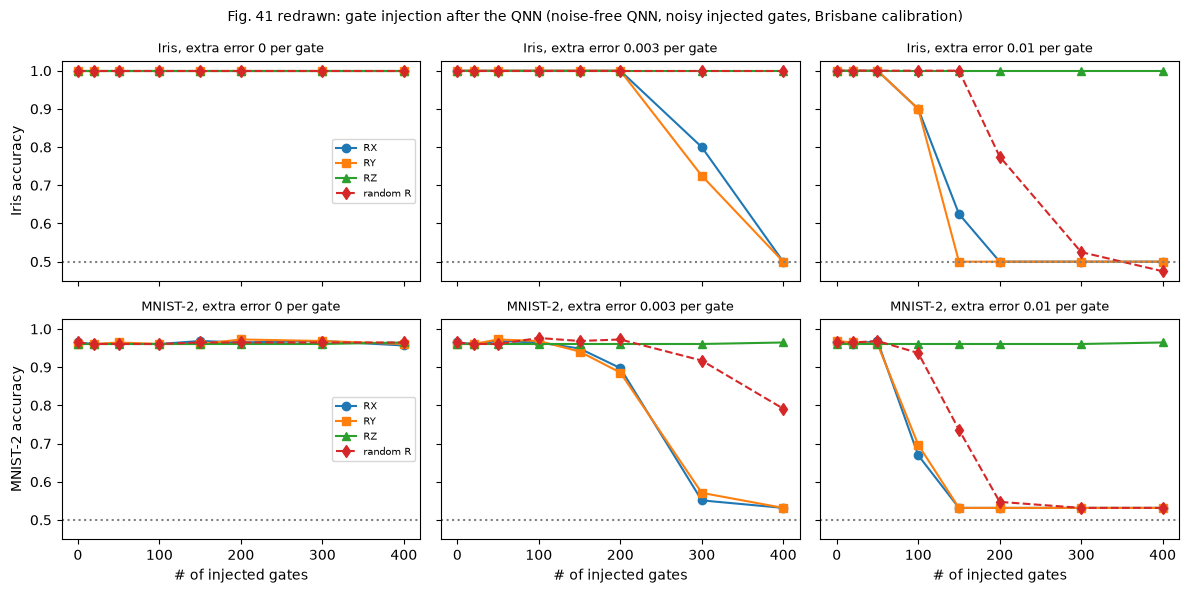

Iris


extra 0                  extra 0.003                    extra 0.01                 
         rx   ry   rz random          rx     ry   rz random         rx   ry   rz random
0       1.0  1.0  1.0    1.0         1.0  1.000  1.0    1.0      1.000  1.0  1.0  1.000
20      1.0  1.0  1.0    1.0         1.0  1.000  1.0    1.0      1.000  1.0  1.0  1.000
50      1.0  1.0  1.0    1.0         1.0  1.000  1.0    1.0      1.000  1.0  1.0  1.000
100     1.0  1.0  1.0    1.0         1.0  1.000  1.0    1.0      0.900  0.9  1.0  1.000
150     1.0  1.0  1.0    1.0         1.0  1.000  1.0    1.0      0.625  0.5  1.0  1.000
200     1.0  1.0  1.0    1.0         1.0  1.000  1.0    1.0      0.500  0.5  1.0  0.775
300     1.0  1.0  1.0    1.0         0.8  0.725  1.0    1.0      0.500  0.5  1.0  0.525
400     1.0  1.0  1.0    1.0         0.5  0.500  1.0    1.0      0.500  0.5  1.0  0.475

MNIST-2


extra 0                      extra 0.003                      extra 0.01                     
         rx     ry     rz random          rx     ry     rz random         rx     ry     rz random
0     0.965  0.961  0.961  0.965       0.965  0.961  0.961  0.965      0.965  0.969  0.961  0.965
20    0.961  0.961  0.961  0.961       0.961  0.961  0.961  0.961      0.961  0.965  0.961  0.965
50    0.961  0.965  0.961  0.961       0.969  0.972  0.961  0.961      0.969  0.961  0.961  0.969
100   0.961  0.961  0.961  0.961       0.965  0.969  0.961  0.976      0.669  0.697  0.961  0.937
150   0.969  0.961  0.961  0.965       0.949  0.941  0.961  0.969      0.531  0.531  0.961  0.736
200   0.965  0.972  0.961  0.965       0.898  0.886  0.961  0.972      0.531  0.531  0.961  0.547
300   0.969  0.969  0.961  0.965       0.551  0.571  0.961  0.917      0.531  0.531  0.961  0.531
400   0.957  0.961  0.965  0.965       0.531  0.531  0.965  0.791      0.531  0.531  0.965  0.531

In [17]:
def injection_curves(dn, rhos, mphys, y, bias, counts, extra_p, kinds=("rx", "ry", "rz", "random"), noisy=True, seed=SEED):
    """Accuracy of the QNN after N injected gates, for every kind of injected block."""
    rs = np.random.default_rng(seed); out = {}
    for kind in kinds:
        accs = []
        if kind == "random":
            blocks = [block_superop(dn, mphys, kind, rng=np.random.default_rng(seed + i), noisy=noisy, extra_p=extra_p) for i in range(max(counts) // 6 + 1)]
        else:
            S = block_superop(dn, mphys, kind, noisy=noisy, extra_p=extra_p)
        for g in counts:
            nb = g // GATES_PER_BLOCK[kind]
            Sl = blocks[:nb] if kind == "random" else [S] * nb
            p1 = np.array([evolve(Sl, r)[1, 1].real for r in rhos])
            pr = dn.device([mphys]).p_read1(p1, mphys) if noisy else p1
            k = rs.binomial(SHOTS, np.clip(pr, 0, 1)) / SHOTS
            accs.append(float(((k + bias > 0.5).astype(int) == y).mean()))
        out[kind] = accs
    return out

mph_q = 0                                           # readout qubit on physical qubit 0 (layout [0, 1] / [0, ..., 7])
rhos_i = ideal_rhos(dm2, Xi_te, w_iris)
t0 = time.time(); rhos_m = ideal_rhos(dm8, Xm_te, w_mnist); print("ideal reduced states of %d MNIST-2 images: %.1f s" % (len(rhos_m), time.time() - t0))
cur_i = {p: injection_curves(dn, rhos_i, mph_q, yi_te, b_iris, GATE_COUNTS, p) for p in INJ_EXTRA}
cur_m = {p: injection_curves(dn, rhos_m, mph_q, ym_te, b_mnist, GATE_COUNTS, p) for p in INJ_EXTRA}
cur_i_ideal = injection_curves(dn, rhos_i, mph_q, yi_te, b_iris, GATE_COUNTS, 0.0, kinds=("rx", "ry"), noisy=False)   # no noise at all: only eps
R["inj_iris"], R["inj_mnist"], R["inj_iris_ideal"] = cur_i, cur_m, cur_i_ideal

fig, ax = plt.subplots(2, len(INJ_EXTRA), figsize=(4 * len(INJ_EXTRA), 6), sharex=True, sharey=True)
for row, (nm, cur) in enumerate([("Iris", cur_i), ("MNIST-2", cur_m)]):
    for col, p in enumerate(INJ_EXTRA):
        a = ax[row, col]
        for kind, st in [("rx", "o-"), ("ry", "s-"), ("rz", "^-"), ("random", "d--")]:
            a.plot(GATE_COUNTS, cur[p][kind], st, label=kind.upper() if kind != "random" else "random R")
        a.axhline(0.5, color="gray", ls=":"); a.set_title("%s, extra error %g per gate" % (nm, p), fontsize=9)
        if col == 0:
            a.set_ylabel("%s accuracy" % nm); a.legend(fontsize=7)
        if row == 1:
            a.set_xlabel("# of injected gates")
plt.suptitle("Fig. 41 redrawn: gate injection after the QNN (noise-free QNN, noisy injected gates, Brisbane calibration)", fontsize=10)
plt.tight_layout(); plt.show()
for nm, cur in [("Iris", cur_i), ("MNIST-2", cur_m)]:
    print(nm); display(pd.concat({"extra %g" % p: pd.DataFrame(cur[p], index=GATE_COUNTS) for p in INJ_EXTRA}, axis=1).round(3))

### 6.1 Parity-check defence (paper Fig. 43-44)

The paper's text describes a small error-detection circuit, not its exact layout. This notebook implements the simplest circuit
that fits the description (`# CHOICE`): an ancilla qubit next to the output qubit; `CNOT(output -> ancilla)` **before** the
injected gates and again **after** them; the ancilla then holds the parity of "output before" and "output after". If the
ancilla reads 1 something flipped the output while the injected gates ran, and the classical post-processing flips the output bit
back. The two extra CNOTs are noisy too, so the defended accuracy starts slightly lower than the undefended one.
Superoperators of the two-qubit block are used exactly as above (`CNOT . pairs^N . CNOT` on the output qubit and its ancilla).
The curves use the noisiest injection level of the previous cell (extra error 1e-2), where the undefended model actually fails.

output qubit: physical 0, ancilla: physical 14 (a neighbour that the QNN does not use)


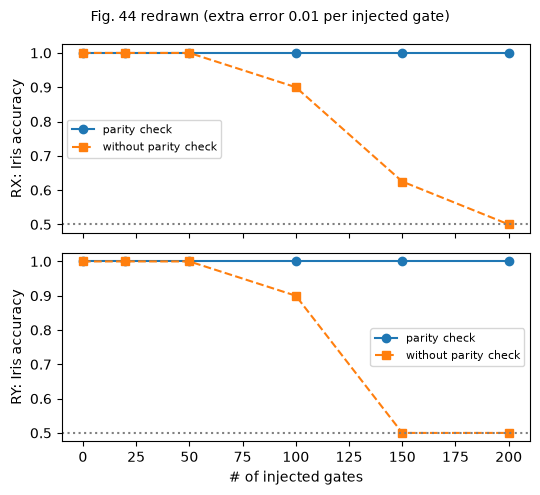

,Rx parity,Rx plain,Ry parity,Ry plain
0,1.0,1.000,1.0,1.0
20,1.0,1.000,1.0,1.0
50,1.0,1.000,1.0,1.0
100,1.0,0.900,1.0,0.9
150,1.0,0.625,1.0,0.5
200,1.0,0.500,1.0,0.5


In [18]:
def parity_curves(dn, rhos, mphys, anc, y, bias, counts, extra_p, kinds=("rx", "ry"), seed=SEED):
    rs = np.random.default_rng(seed); d2 = dn.device([mphys, anc], extra=dep(extra_p), method="superop")
    c = QuantumCircuit(2); c.cx(0, 1)
    tq = transpile(c, dn.backend, initial_layout=[mphys, anc], optimization_level=0)
    cc, _ = d2.compact(tq); cc.save_superop()
    S_cx = np.array(d2.sim.run(cc).result().data(0)["superop"].data)
    p10o, p01o = d2.readout[mphys]; p10a, p01a = d2.readout[anc]
    Co = np.array([[1 - p10o, p01o], [p10o, 1 - p01o]]); Ca = np.array([[1 - p10a, p01a], [p10a, 1 - p01a]])
    out = {}
    for kind in kinds:
        blk = inject_block(kind); sc = QuantumCircuit(2)
        for inst in blk.data:
            sc.append(inst.operation, [0])
        sc.save_superop(); S_pair = np.array(d2.sim.run(sc).result().data(0)["superop"].data)
        accs = []
        for g in counts:
            nb = g // 2; M = S_cx @ np.linalg.matrix_power(S_pair, nb) @ S_cx
            pc = []
            for r in rhos:
                rho2 = np.kron(np.diag([1.0, 0.0]), r)                     # ancilla (qubit 1) in |0>, output qubit 0
                f = (M @ rho2.reshape(-1, order="F")).reshape(4, 4, order="F")
                P = np.diag(f).real.reshape(2, 2)                          # P[anc, out]
                Pm = np.einsum("ma,no,ao->nm", Ca, Co, P)                  # measured: Pm[out_meas, anc_meas]
                pc.append(Pm[1, 0] + Pm[0, 1])                             # corrected bit = out XOR anc
            k = rs.binomial(SHOTS, np.clip(pc, 0, 1)) / SHOTS
            accs.append(float(((k + bias > 0.5).astype(int) == y).mean()))
        out[kind] = accs
    return out

anc = next(q for q in sorted(dn.adj[mph_q]) if q not in (0, 1))
print("output qubit: physical %d, ancilla: physical %d (a neighbour that the QNN does not use)" % (mph_q, anc))
cnt44 = [g for g in GATE_COUNTS if g <= 200]
P_STRONG = INJ_EXTRA[-1]
par = parity_curves(dn, rhos_i, mph_q, anc, yi_te, b_iris, cnt44, P_STRONG)
nopar = {k: v[:len(cnt44)] for k, v in cur_i[P_STRONG].items() if k in ("rx", "ry")}
R["parity"], R["noparity"], R["cnt44"] = par, nopar, cnt44
fig, ax = plt.subplots(2, 1, figsize=(5.5, 5), sharex=True, sharey=True)
for a, kind in zip(ax, ["rx", "ry"]):
    a.plot(cnt44, par[kind], "o-", label="parity check"); a.plot(cnt44, nopar[kind], "s--", label="without parity check")
    a.set_ylabel("%s: Iris accuracy" % kind.upper()); a.legend(fontsize=8); a.axhline(0.5, color="gray", ls=":")
ax[1].set_xlabel("# of injected gates"); plt.suptitle("Fig. 44 redrawn (extra error %g per injected gate)" % P_STRONG, fontsize=10); plt.tight_layout(); plt.show()
display(pd.DataFrame({"Rx parity": par["rx"], "Rx plain": nopar["rx"], "Ry parity": par["ry"], "Ry plain": nopar["ry"]}, index=cnt44).round(3))

## 7. Readout falsification (paper Section 7, Fig. 45-46)

The last step of a QML pipeline turns measurement counts into a decision. Three cheap attacks on that step:

1. **Fewer shots than reported** (attack A+C in the paper's Fig. 7): the probability estimate gets noisier. The paper expects
   little effect for small QNNs and more for large ones.
2. **Changed measurement basis**: the model was trained to be read in the Z basis; reading X or Y gives unrelated numbers.
3. **Bit flips on the way back** (man in the middle): a fraction `d` of the returned bits is flipped at random.

### 7.1 Number of shots (Fig. 45)

Seven "backends" in the paper, five here: an ideal Aer sampler, PennyLane's `default.qubit` with finite shots, and the
simulated IBM Brisbane / Kyoto / Osaka. For the noisy devices the exact noisy distribution of the readout qubit is computed once
(density matrix, read-out errors included) and the shot statistics are drawn from it, which is statistically identical to running
that many shots. Accuracy is averaged over repeated shot draws.

ideal samplers: 694 s


  Brisbane: 60 noisy 8-qubit simulations, 71 s


  Osaka: 60 noisy 8-qubit simulations, 67 s


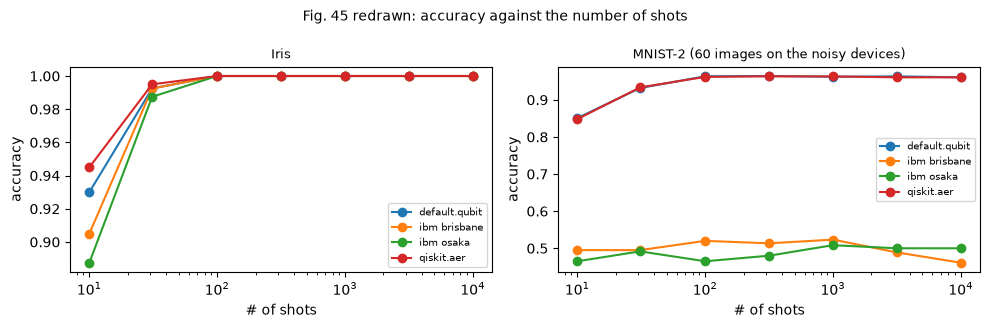

shots                  10     31     100    316    1000   3162   10000
data    backend                                                       
Iris    default.qubit  0.930  0.992  1.000  1.000  1.000  1.000  1.000
        ibm brisbane   0.905  0.992  1.000  1.000  1.000  1.000  1.000
        ibm osaka      0.888  0.988  1.000  1.000  1.000  1.000  1.000
        qiskit.aer     0.945  0.995  1.000  1.000  1.000  1.000  1.000
MNIST-2 default.qubit  0.851  0.932  0.963  0.964  0.962  0.963  0.961
        ibm brisbane   0.495  0.495  0.520  0.513  0.523  0.489  0.461
        ibm osaka      0.465  0.492  0.465  0.480  0.508  0.500  0.500
        qiskit.aer     0.848  0.933  0.962  0.963  0.963  0.961  0.961

In [19]:
rs_shot = np.random.default_rng(SEED + 11)

# the first MNIST_NOISY_N test images (balanced classes) go through the noisy 8-qubit device simulations
idx_n = np.concatenate([np.where(ym_te == 0)[0][:MNIST_NOISY_N // 2], np.where(ym_te == 1)[0][:MNIST_NOISY_N - MNIST_NOISY_N // 2]])
_mn_cache = {}
def mnist_noisy_states(name):
    """Reduced density matrix of the readout qubit for the noisy 8-qubit MNIST-2 QNN on backend `name` (layout 0 ... 7)."""
    if name not in _mn_cache:
        t0 = time.time(); out = []
        for k in idx_n:
            tq = prepare(qiskit_qnn(Xm_te[k], w_mnist), name, list(range(8)))
            out.append(noisy_state(get_dn(name), tq))
        _mn_cache[name] = (np.array([o[0] for o in out]), out[0][1])
        print("  %s: %d noisy 8-qubit simulations, %.0f s" % (name, len(idx_n), time.time() - t0))
    return _mn_cache[name]

# PennyLane qnodes for finite-shot sampling (no gradients needed)
def make_qnode_shots(n):
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev, diff_method=None)
    def circuit(x, w):
        qml.AmplitudeEmbedding(x, wires=range(n), normalize=True)
        qml.StronglyEntanglingLayers(w, wires=range(n))
        return qml.probs(wires=0)
    return circuit
circ2_shots, circ8_shots = make_qnode_shots(2), make_qnode_shots(8)

def acc_from_p1_read(p1_read, y, bias, shots, repeats=N_SHOT_REPEATS):
    a = []
    for _ in range(repeats):
        k = rs_shot.binomial(shots, np.clip(p1_read, 0, 1)) / shots
        a.append(((k + bias > 0.5).astype(int) == y).mean())
    return float(np.mean(a))

def pl_shot_accuracy(circuit, w, X, y, bias, shots, repeats):
    """PennyLane default.qubit with a finite number of shots (real sampling)."""
    c = qml.set_shots(circuit, shots=shots); a = []
    for _ in range(repeats):
        p1 = np.array(c(pnp.array(X, requires_grad=False), pnp.array(w, requires_grad=False)))[:, 1]
        a.append(((p1 + bias > 0.5).astype(int) == y).mean())
    return float(np.mean(a))

_aer_circs = {}
def aer_shot_accuracy(X, w, y, bias, shots, repeats, key):
    """Qiskit Aer (ideal) sampling of the measured circuits (transpiled once per data set)."""
    sim = AerSimulator(seed_simulator=SEED); a = []
    if key not in _aer_circs:
        _aer_circs[key] = [transpile(qiskit_qnn(x, w), basis_gates=["u", "cx"], optimization_level=0) for x in X]
    circs = _aer_circs[key]
    for r in range(repeats):
        res = sim.run(circs, shots=shots, seed_simulator=SEED + r).result()
        p1 = np.array([res.get_counts(i).get("1", 0) / shots for i in range(len(circs))])
        a.append(((p1 + bias > 0.5).astype(int) == y).mean())
    return float(np.mean(a))

n_aer_m = min(len(Xm_te), 40 if FAST_MODE else 254)    # images for the (slower) circuit-level Aer sampler
shot_rows = []
t0 = time.time()
for sh in SHOT_GRID:
    rep = max(1, N_SHOT_REPEATS if sh <= 1000 else max(1, N_SHOT_REPEATS // 3))
    shot_rows.append(dict(shots=sh, data="Iris", backend="qiskit.aer", acc=aer_shot_accuracy(Xi_te, w_iris, yi_te, b_iris, sh, rep, "iris")))
    shot_rows.append(dict(shots=sh, data="Iris", backend="default.qubit", acc=pl_shot_accuracy(circ2_shots, w_iris, Xi_te, yi_te, b_iris, sh, rep)))
    shot_rows.append(dict(shots=sh, data="MNIST-2", backend="qiskit.aer", acc=aer_shot_accuracy(Xm_te[:n_aer_m], w_mnist, ym_te[:n_aer_m], b_mnist, sh, rep, "mnist")))
    shot_rows.append(dict(shots=sh, data="MNIST-2", backend="default.qubit", acc=pl_shot_accuracy(circ8_shots, w_mnist, Xm_te, ym_te, b_mnist, sh, rep)))
print("ideal samplers: %.0f s" % (time.time() - t0))
for name in SWEEP_BACKENDS:
    dnx = get_dn(name)
    # Iris on this backend
    st = [noisy_state(dnx, prepare(qiskit_qnn(x, w_iris), name, good_layout(name))) for x in Xi_te]
    p_i = dnx.device([st[0][1]]).p_read1(np.array([s[0][1, 1].real for s in st]), st[0][1])
    rhos_n, mph_n = mnist_noisy_states(name)
    p_m = dnx.device([mph_n]).p_read1(np.array([r[1, 1].real for r in rhos_n]), mph_n)
    for sh in SHOT_GRID:
        rep = max(1, N_SHOT_REPEATS if sh <= 1000 else max(1, N_SHOT_REPEATS // 3))
        shot_rows.append(dict(shots=sh, data="Iris", backend="ibm " + name.lower(), acc=acc_from_p1_read(p_i, yi_te, b_iris, sh, rep)))
        shot_rows.append(dict(shots=sh, data="MNIST-2", backend="ibm " + name.lower(), acc=acc_from_p1_read(p_m, ym_te[idx_n], b_mnist, sh, rep)))
shots_df = pd.DataFrame(shot_rows); R["shots"] = shots_df
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3), sharey=False)
for a, data in zip(ax, ["Iris", "MNIST-2"]):
    for be, g in shots_df[shots_df.data == data].groupby("backend"):
        a.plot(g.shots, g.acc, "o-", label=be)
    a.set_xscale("log"); a.set_xlabel("# of shots"); a.set_ylabel("accuracy"); a.set_title(data + (" (%d images on the noisy devices)" % len(idx_n) if data == "MNIST-2" else ""), fontsize=9); a.legend(fontsize=7)
plt.suptitle("Fig. 45 redrawn: accuracy against the number of shots", fontsize=10); plt.tight_layout(); plt.show()
display(shots_df.pivot_table(index=["data", "backend"], columns="shots", values="acc").round(3))

### 7.2 Changed measurement basis and bit flips (Fig. 46)

The model is evaluated on an ideal simulator with 1000 shots (`# CHOICE`, the paper does not say which backend). (a) The
output qubit is read in the Pauli-Z basis it was trained for, then in X and in Y (`P1 = (1 - <P>)/2`, the same decision rule). (b) A fraction
`d` of the returned data is disrupted before the decision. The paper's text allows two readings (Section 7.3: "flipping a
percentage of the returned measurements"; Section 7.1: "randomly swapping and/or substituting stochastic noise for real measurement
results"), so both are run: (b1) every returned shot is flipped with probability `d` (which shrinks the probability estimate
but keeps its sign, so the decision survives until `d` approaches 0.5); (b2) with probability `d` the whole returned result of an input is replaced by a random bit.

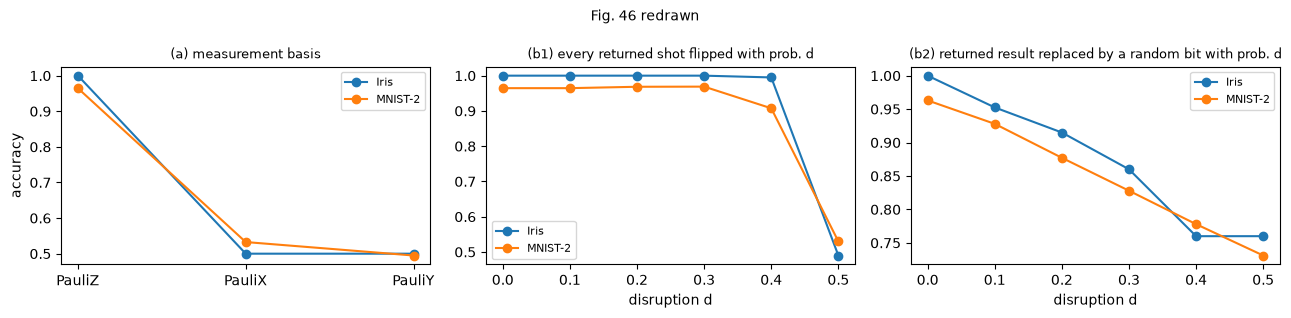

data,Iris,MNIST-2
basis,,
PauliX,0.5,0.533
PauliY,0.5,0.495
PauliZ,1.0,0.965


acc_flip_shots         acc_replace_result        
data                 Iris MNIST-2               Iris MNIST-2
disruption                                                  
0.0                 1.000   0.965              1.000   0.963
0.1                 1.000   0.965              0.952   0.928
0.2                 1.000   0.969              0.915   0.877
0.3                 1.000   0.969              0.860   0.828
0.4                 0.995   0.907              0.760   0.778
0.5                 0.490   0.530              0.760   0.731

In [20]:
SH46 = 1000
def expval_pauli(n, X, w, which):
    dev = qml.device("default.qubit", wires=n)
    obs = {"Z": qml.PauliZ, "X": qml.PauliX, "Y": qml.PauliY}[which]
    @qml.qnode(dev, interface="autograd", diff_method="backprop")
    def c(x, w):
        qml.AmplitudeEmbedding(x, wires=range(n), normalize=True); qml.StronglyEntanglingLayers(w, wires=range(n))
        return qml.expval(obs(0))
    return np.array(c(X, w))

rows46a, rows46b = [], []
DISR = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
for data, n, X, y, w, b in [("Iris", 2, Xi_te, yi_te, w_iris, b_iris), ("MNIST-2", 8, Xm_te, ym_te, w_mnist, b_mnist)]:
    for which in ["Z", "X", "Y"]:
        p1 = (1 - expval_pauli(n, X, w, which)) / 2
        rows46a.append(dict(data=data, basis="Pauli" + which, acc=acc_from_p1_read(p1, y, b, SH46, 10)))
    p1z = (1 - expval_pauli(n, X, w, "Z")) / 2
    for d in DISR:
        # reading 1 (literal): every returned shot is flipped with probability d before the decision
        a1 = acc_from_p1_read(p1z * (1 - d) + (1 - p1z) * d, y, b, SH46, 10)
        # reading 2 (Sec. 7.1, attack C "random swapping / substituting stochastic noise"): with probability d the whole returned
        # result of an input is replaced by a random bit
        a2 = []
        for _ in range(10):
            k = rs_shot.binomial(SH46, np.clip(p1z, 0, 1)) / SH46
            dec = ((k + b > 0.5).astype(int))
            repl = rs_shot.random(len(dec)) < d
            dec = np.where(repl, rs_shot.integers(0, 2, len(dec)), dec)
            a2.append((dec == y).mean())
        rows46b.append(dict(data=data, disruption=d, acc_flip_shots=a1, acc_replace_result=float(np.mean(a2))))
d46a, d46b = pd.DataFrame(rows46a), pd.DataFrame(rows46b); R["d46a"], R["d46b"] = d46a, d46b
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for data, g in d46a.groupby("data"):
    ax[0].plot(g.basis, g.acc, "o-", label=data)
for data, g in d46b.groupby("data"):
    ax[1].plot(g.disruption, g.acc_flip_shots, "o-", label=data); ax[2].plot(g.disruption, g.acc_replace_result, "o-", label=data)
ax[0].set_ylabel("accuracy"); ax[0].set_title("(a) measurement basis", fontsize=9)
ax[1].set_title("(b1) every returned shot flipped with prob. d", fontsize=9); ax[2].set_title("(b2) returned result replaced by a random bit with prob. d", fontsize=9)
for a in ax[1:]:
    a.set_xlabel("disruption d")
for a in ax:
    a.legend(fontsize=8)
plt.suptitle("Fig. 46 redrawn", fontsize=10); plt.tight_layout(); plt.show()
display(d46a.pivot(index="basis", columns="data", values="acc").round(3))
display(d46b.pivot(index="disruption", columns="data", values=["acc_flip_shots", "acc_replace_result"]).round(3))

## 8. What the paper claims and what was measured here

Every statement of the paper that can be tested without a quantum computer is listed with the paper's number or qualitative
claim, the number measured in this run, and a verdict. Rules (fixed before looking at the numbers): a numeric claim is
**reproduced** when the notebook is within 0.02 (accuracy) or within 10 % (circuit depth); otherwise **not reached** (below the
paper) or **exceeded** (above it). A qualitative claim is **reproduced** when the stated condition holds in the run, otherwise
**not reproduced**. Claims that need hardware, other software, or an experiment not attempted here are **cannot be checked**.
A claim marked *(model)* depends on the crosstalk model and the assumed coupling rates of section 4 and is therefore
a statement about the model, not about a real chip.

In [21]:
def acc_at(df, **kw):
    q = df
    for k, v in kw.items():
        q = q[q[k] == v]
    return float(q.acc.iloc[0])

CL = []   # (section, claim, paper, measured, verdict)
def add(section, claim, paper, measured, verdict):
    CL.append(dict(section=section, claim=claim, paper=paper, notebook=measured, verdict=verdict))
def numeric(paper_val, nb_val, tol):
    if abs(nb_val - paper_val) <= tol:
        return "reproduced"
    return "exceeded" if nb_val > paper_val else "not reached"
def cond(ok):
    return "reproduced" if ok else "not reproduced"

# --- Table 3 / circuits
add("Table 3", "Iris QNN: 13 parameters", "13", str(R["params_iris"]), cond(R["params_iris"] == 13))
add("Table 3", "Iris circuit depth", "16", str(R["depth_iris"]), "reproduced" if abs(R["depth_iris"] - 16) <= 1.6 else "not reached" if R["depth_iris"] < 16 else "exceeded")
add("Table 3", "MNIST-2 circuit depth", "511", str(R["depth_mnist"]), "reproduced" if abs(R["depth_mnist"] - 511) <= 51 else "not reproduced")
add("Table 3", "MNIST-2 QNN: 961 parameters; 960 + 320 gates", "961 / 960 / 320", "49 params; %d u3 + %d cx" % (st_m["one_qubit"], st_m["two_qubit"]), "not reproduced")
add("Fig. 32 caption", "192 gates fit into T2 = 127.37 us at 660 ns", "192", str(R["gates_before_decoherence"]), numeric(192, R["gates_before_decoherence"], 0))
# --- clean accuracy
sh_max = max(SHOT_GRID); sh_min = min(SHOT_GRID)
iris_all = shots_df[(shots_df.data == "Iris")]
add("Fig. 45a", "Iris QNN accuracy 0.9 ... 1 on every backend and shot count", "0.9 - 1.0", "min %.3f, max %.3f" % (iris_all.acc.min(), iris_all.acc.max()), cond(iris_all.acc.min() >= 0.9 - TOL_ACC))
m_ideal = shots_df[(shots_df.data == "MNIST-2") & (shots_df.backend == "default.qubit")]
add("Fig. 45b", "MNIST-2, ideal simulator, 10^4 shots: accuracy around 0.9", "~0.90", "%.3f" % acc_at(m_ideal, shots=sh_max), numeric(0.90, acc_at(m_ideal, shots=sh_max), TOL_ACC))
add("Fig. 45b", "MNIST-2, ideal simulator, 10 shots: accuracy around 0.8", "~0.80", "%.3f" % acc_at(m_ideal, shots=sh_min), numeric(0.80, acc_at(m_ideal, shots=sh_min), TOL_ACC))
m_noisy = shots_df[(shots_df.data == "MNIST-2") & shots_df.backend.str.startswith("ibm")]
add("Fig. 45b", "MNIST-2 on simulated IBM devices is a random classifier, independent of shots", "~0.3 - 0.5", "%.3f ... %.3f" % (m_noisy.acc.min(), m_noisy.acc.max()), cond(m_noisy.acc.max() <= 0.6 and m_noisy.acc.min() >= 0.3))
# --- crosstalk
x43 = R["xt"].set_index(["device", "scenario"])
eff_n, eff_b = x43.loc[("Nairobi", "adv. near"), "crosstalk_effect"], x43.loc[("Brisbane", "adv. near"), "crosstalk_effect"]
eff_nf = x43.loc[("Nairobi", "adv. far"), "crosstalk_effect"]
add("Fig. 34 (model)", "crosstalk drive changes the QNN output on Nairobi (near attacker)", "visible shift", "mean |dP1| = %.3f (zeta %g kHz)" % (eff_n, ZETA_KHZ["Nairobi"]), cond(eff_n >= 0.05))
add("Fig. 34 (model)", "much weaker change on Brisbane, none for a far attacker", "no visible change", "Brisbane near %.3f (Nairobi %.3f), Nairobi far %.3f" % (eff_b, eff_n, eff_nf), cond(eff_b <= eff_n / 3 and eff_nf <= 0.005))
add("Fig. 34", "measured shifts on the real ibm_nairobi / ibm_brisbane chips", "Fig. 34a/b", "hardware retired / not accessible", "cannot be checked")
add("Fig. 35 (model)", "MNIST-2 confidence is random with and without the injected circuit", "random", "mean |P1-0.5|: " + ", ".join("%s %.3f" % (k.split(" [")[0], v) for k, v in R["mnist_xt_conf"].items() if k != "ideal simulator"),
    cond(max(v for k, v in R["mnist_xt_conf"].items() if k != "ideal simulator") <= 0.05))
sw_ = R["xt_sweep"]; ks_n = sw_[(sw_.device == "Nairobi") & (sw_.sweep == "K")].set_index("value").effect
add("Sec. 5.2.1 (lit.)", "effect needs more than ~5 repetitions of the drive (Deshpande et al.)", "K > 5", "effect K=2: %.3f, K=10: %.3f, K=30: %.3f" % (ks_n.get(2, np.nan), ks_n.get(10, np.nan), ks_n.get(30, np.nan)),
    cond(ks_n.get(10, 0) > ks_n.get(2, 0)))
# --- Fig 36
s36 = R["sweep36"]["Brisbane"]; lv = NOISE_LEVELS
g = lambda kind, p: s36[kind][lv.index(p)]
add("Fig. 36", "amplitude damping at level 0.2 degrades the QNN to a random classifier", "~0.5", "%.3f" % g("amplitude damping", 0.2), cond(g("amplitude damping", 0.2) <= 0.6))
add("Fig. 36", "depolarizing noise: accuracy stays above 0.9 up to level 0.1", ">0.9 for p <= 0.1", "min %.3f" % min(g("depolarizing", p) for p in lv if p <= 0.1), cond(min(g("depolarizing", p) for p in lv if p <= 0.1) >= 0.9))
add("Fig. 36", "phase damping: accuracy stays above 0.9 until level 0.3", ">0.9 for p <= 0.3", "min %.3f" % min(g("phase damping", p) for p in lv if p <= 0.3), cond(min(g("phase damping", p) for p in lv if p <= 0.3) >= 0.9))
add("Fig. 36", "amplitude + phase damping: accuracy below 0.9 already at level 0.1", "<0.9 at p = 0.1", "%.3f" % g("amplitude + phase damping", 0.1), cond(g("amplitude + phase damping", 0.1) < 0.9))
sev = {k: np.mean(s36[k]) for k in KINDS[:3]}                     # the three single channels the paper ranks in the text
add("Fig. 36", "of depolarizing / phase / amplitude damping: amplitude damping is the most severe, phase damping the least", "amp. damping worst, phase damping best",
    " < ".join("%s %.2f" % (k.split()[0], v) for k, v in sorted(sev.items(), key=lambda kv: kv[1])) + " (mean accuracy over levels, worst first)",
    cond(min(sev, key=sev.get) == "amplitude damping" and max(sev, key=sev.get) == "phase damping"))
# --- Fig 41, 44
p_cal, p_str = INJ_EXTRA[0], INJ_EXTRA[-1]
ci, cm = R["inj_iris"][p_str], R["inj_mnist"][p_str]; cic, cmc = R["inj_iris"][p_cal], R["inj_mnist"][p_cal]
add("Fig. 41", "Rz injection does not affect accuracy", "no effect", "extra %g: Iris %.3f -> %.3f, MNIST-2 %.3f -> %.3f" % (p_str, ci["rz"][0], ci["rz"][-1], cm["rz"][0], cm["rz"][-1]),
    cond(abs(ci["rz"][-1] - ci["rz"][0]) <= TOL_ACC and abs(cm["rz"][-1] - cm["rz"][0]) <= TOL_ACC))
add("Fig. 41", "Rx / Ry injection reduces accuracy; calibrated Brisbane noise only", "falls towards 0.5", "Iris Rx %.3f, Ry %.3f; MNIST-2 Rx %.3f, Ry %.3f at %d gates" % (cic["rx"][-1], cic["ry"][-1], cmc["rx"][-1], cmc["ry"][-1], GATE_COUNTS[-1]),
    cond(cic["rx"][-1] < cic["rx"][0] - 0.1 and cic["ry"][-1] < cic["ry"][0] - 0.1))
add("Fig. 41", "Rx / Ry injection reduces accuracy; with %g extra error per injected gate" % p_str, "falls towards 0.5", "Iris Rx %.3f, Ry %.3f; MNIST-2 Rx %.3f, Ry %.3f at %d gates" % (ci["rx"][-1], ci["ry"][-1], cm["rx"][-1], cm["ry"][-1], GATE_COUNTS[-1]),
    cond(ci["rx"][-1] < ci["rx"][0] - 0.1 and ci["ry"][-1] < ci["ry"][0] - 0.1))
d_i = np.mean([np.mean(ci[k][0] - np.array(ci[k][1:])) for k in ("rx", "ry")]); d_m = np.mean([np.mean(cm[k][0] - np.array(cm[k][1:])) for k in ("rx", "ry")])
add("Fig. 41", "Iris is more susceptible to injection than MNIST-2", "Iris drops more", "mean accuracy drop over all gate counts > 0: Iris %.3f vs MNIST-2 %.3f (extra %g)" % (d_i, d_m, p_str), cond(d_i > d_m + TOL_ACC))
add("Fig. 41", "equivalence checking cannot see the injection (identity up to eps = 1e-5)", "ideal accuracy unchanged", "noise-free Ry: %.3f -> %.3f" % (R["inj_iris_ideal"]["ry"][0], R["inj_iris_ideal"]["ry"][-1]),
    cond(abs(R["inj_iris_ideal"]["ry"][-1] - R["inj_iris_ideal"]["ry"][0]) <= TOL_ACC))
pa, npa = R["parity"], R["noparity"]
add("Fig. 44", "parity check keeps accuracy at its initial value for up to 200 injected gates", "stable", "parity Rx %.3f -> %.3f, Ry %.3f -> %.3f; plain Rx %.3f, Ry %.3f at 200" % (pa["rx"][0], pa["rx"][-1], pa["ry"][0], pa["ry"][-1], npa["rx"][-1], npa["ry"][-1]),
    cond(pa["rx"][-1] >= pa["rx"][0] - 0.05 and pa["ry"][-1] >= pa["ry"][0] - 0.05 and pa["rx"][-1] > npa["rx"][-1] and pa["ry"][-1] > npa["ry"][-1]))
# --- Fig 46
a46 = R["d46a"].pivot(index="basis", columns="data", values="acc")
add("Fig. 46a", "reading Pauli X or Y instead of Z lowers accuracy (both data sets)", "lower", "Iris Z/X/Y %.2f/%.2f/%.2f; MNIST-2 %.2f/%.2f/%.2f" % tuple(list(a46["Iris"].loc[["PauliZ", "PauliX", "PauliY"]]) + list(a46["MNIST-2"].loc[["PauliZ", "PauliX", "PauliY"]])),
    cond(all(a46[d].loc[b] < a46[d].loc["PauliZ"] - TOL_ACC for d in a46.columns for b in ["PauliX", "PauliY"])))
b1 = R["d46b"].pivot(index="disruption", columns="data", values="acc_flip_shots"); b2 = R["d46b"].pivot(index="disruption", columns="data", values="acc_replace_result")
add("Fig. 46b", "disruption lowers accuracy on both data sets (reading b1: every shot flipped with prob. d)", "decreases", "d = 0.2 / 0.5: Iris %.2f / %.2f, MNIST-2 %.2f / %.2f" % (b1["Iris"].loc[0.2], b1["Iris"].loc[0.5], b1["MNIST-2"].loc[0.2], b1["MNIST-2"].loc[0.5]),
    cond(b1["Iris"].loc[0.2] < b1["Iris"].loc[0.0] - TOL_ACC and b1["MNIST-2"].loc[0.2] < b1["MNIST-2"].loc[0.0] - TOL_ACC))
add("Fig. 46b", "disruption lowers accuracy on both data sets (reading b2: result replaced by a random bit with prob. d)", "decreases", "d = 0.2 / 0.5: Iris %.2f / %.2f, MNIST-2 %.2f / %.2f" % (b2["Iris"].loc[0.2], b2["Iris"].loc[0.5], b2["MNIST-2"].loc[0.2], b2["MNIST-2"].loc[0.5]),
    cond(b2["Iris"].loc[0.2] < b2["Iris"].loc[0.0] - TOL_ACC and b2["MNIST-2"].loc[0.2] < b2["MNIST-2"].loc[0.0] - TOL_ACC))
add("Fig. 46b", "MNIST-2 is more sensitive to disruption than Iris (reading b2, loss at d = 0.5)", "MNIST-2 drops more", "loss Iris %.3f vs MNIST-2 %.3f" % (b2["Iris"].loc[0.0] - b2["Iris"].loc[0.5], b2["MNIST-2"].loc[0.0] - b2["MNIST-2"].loc[0.5]),
    cond((b2["MNIST-2"].loc[0.0] - b2["MNIST-2"].loc[0.5]) > (b2["Iris"].loc[0.0] - b2["Iris"].loc[0.5]) + TOL_ACC))
# --- shots: expected qualitative statement
add("Sec. 7.2", "reducing shots has little effect on the small Iris QNN", "little effect", "Iris ideal: %.3f at %d shots vs %.3f at %d shots" % (acc_at(iris_all[iris_all.backend == "default.qubit"], shots=sh_min), sh_min, acc_at(iris_all[iris_all.backend == "default.qubit"], shots=sh_max), sh_max),
    cond(acc_at(iris_all[iris_all.backend == "default.qubit"], shots=sh_min) >= acc_at(iris_all[iris_all.backend == "default.qubit"], shots=sh_max) - 0.1))
# --- not attempted
add("Fig. 42", "approximate transpilation (QSearch/BQSKit) lowers QNN accuracy with the error tolerance", "Fig. 42", "BQSKit not available", "cannot be checked")
add("Chapter 4, Sec. 6.1.1", "robust encodings for quantum kernels; QTrojan on kernels", "Fig. 15-29, 39-40", "other experiment family, not attempted", "cannot be checked")

verdicts = pd.DataFrame(CL)
pd.set_option("display.max_colwidth", 110)
display(verdicts)
print(verdicts.verdict.value_counts().to_string())
print("\nClassical baselines on the same inputs (not in the paper): Iris %.3f, MNIST-2 %.3f; QNN on an ideal simulator: Iris %.3f, MNIST-2 %.3f"
      % (R["baseline_iris"], R["baseline_mnist"], R["iris_test_acc_victim"], R["mnist_test_acc"]))
print("\nTotal run time: %.1f minutes" % ((time.time() - T_START) / 60))

,section,claim,paper,notebook,verdict
0,Table 3,Iris QNN: 13 parameters,13,13,reproduced
1,Table 3,Iris circuit depth,16,13,not reached
2,Table 3,MNIST-2 circuit depth,511,513,reproduced
3,Table 3,MNIST-2 QNN: 961 parameters; 960 + 320 gates,961 / 960 / 320,49 params; 303 u3 + 263 cx,not reproduced
4,Fig. 32 caption,192 gates fit into T2 = 127.37 us at 660 ns,192,192,reproduced
5,Fig. 45a,Iris QNN accuracy 0.9 ... 1 on every backend and shot count,0.9 - 1.0,"min 0.887, max 1.000",reproduced
6,Fig. 45b,"MNIST-2, ideal simulator, 10^4 shots: accuracy around 0.9",~0.90,0.961,exceeded
7,Fig. 45b,"MNIST-2, ideal simulator, 10 shots: accuracy around 0.8",~0.80,0.851,exceeded
8,Fig. 45b,"MNIST-2 on simulated IBM devices is a random classifier, independent of shots",~0.3 - 0.5,0.461 ... 0.523,reproduced
9,Fig. 34 (model),crosstalk drive changes the QNN output on Nairobi (near attacker),visible shift,mean |dP1| = 0.270 (zeta 100 kHz),reproduced


verdict
reproduced           19
not reproduced        7
cannot be checked     3
exceeded              2
not reached           1

Classical baselines on the same inputs (not in the paper): Iris 1.000, MNIST-2 1.000; QNN on an ideal simulator: Iris 1.000, MNIST-2 0.961

Total run time: 49.8 minutes


## 9. Reading the paper critically

One more experiment before the discussion, because it tests the premise of section 6: does an ordinary transpiler
leave the injected "identity" pairs in the circuit? The cell below counts the `sx` gates (the noisy ones) in a circuit with 50
injected `Rx` pairs after transpilation at different optimisation levels.

In [22]:
base = QuantumCircuit(1)
for _ in range(50):
    base.rx(np.pi / 2 + EPS_INJECT, 0); base.rx(-np.pi / 2, 0)
rows = []
for lvl in [0, 1, 2, 3]:
    t = transpile(base, basis_gates=["rz", "sx", "x"], optimization_level=lvl, seed_transpiler=SEED)
    rows.append(dict(optimization_level=lvl, sx_gates=t.count_ops().get("sx", 0), rz_gates=t.count_ops().get("rz", 0), depth=t.depth()))
inj_opt = pd.DataFrame(rows); display(inj_opt)
R["inj_opt"] = inj_opt

,optimization_level,sx_gates,rz_gates,depth
0,0,200,300,500
1,1,2,3,5
2,2,2,3,5
3,3,2,3,5


**What the experiments support.**

* The QNN, its data and the training budget follow the paper, and the two implementations (PennyLane, Qiskit) agree to machine
  precision. The generic-basis depth of the 8-qubit circuit (513) is within 0.4 % of the paper's 511; the paper's gate counts and the
  parameter count of 961 for MNIST-2 cannot be matched by any natural counting we tried, so they are reported as "not reproduced".
* Most *qualitative* conclusions of Chapters 5 to 7 reproduce on simulated devices: noise channels differ in how harmful they are
  (amplitude damping at level 0.2 and amplitude + phase damping at 0.1 already give a random classifier, as in Fig. 36),
  `Rz` injection is free while `Rx` and `Ry` injection are not, a parity check recovers the output, the 8-qubit amplitude-encoded QNN is
  unusable on a Brisbane-class noise model with or without an attacker, reading the wrong Pauli basis destroys accuracy, shot reduction
  matters for MNIST-2 (ideal accuracy 0.96 at 10^4 shots, about 0.85 at 10 shots) but hardly for Iris, and the ideal QNNs reach or exceed
  the accuracies of the paper's Fig. 45 (our MNIST-2 model is trained for the full 50 epochs and ends above the paper's 0.9).
* Several statements do **not** reproduce, and the reasons are informative: depolarizing and phase damping hurt earlier than in Fig. 36 with our
  definition of "noise level"; with the *calibrated* Brisbane gate errors alone even 400 injected gates do not change a decision (the
  paper's collapse needs a per-gate error of order 1e-2, 30 times the calibration); the paper's finding that Iris is more
  susceptible to injection than MNIST-2 is not seen (here both lose accuracy at the same gate count, which is what one expects when
  the injected noise acts on one qubit after the QNN and mainly shrinks the probability towards 0.5); and flipping
  returned *shots* (reading b1) leaves decisions untouched until `d` is close to 0.5. The table in section 8 gives the per-claim numbers.

**What the experiments do not show.**

1. **The crosstalk result is a model, not a measurement.** The paper's central hardware observation (Nairobi yes, Brisbane no)
   depends on two numbers that the paper does not report and a simulator cannot know: the coupling strength between neighbouring
   qubits and which physical qubits the scheduler gave to victim and attacker. In this notebook those are set by `ZETA_KHZ` and the
   placement in `SETUP`, so "reproduced (model)" means only that the model behaves as the paper's explanation says it should
   (effect grows with coupling and with the length of the drive, vanishes for non-neighbours). The sweep in section 4.4 shows the
   threshold; the paper's claim that the threat "is not completely ruled out" is the right way to read it.
2. **The idle-time control matters.** In the simulation a long attacker circuit alone (no coupling at all) already lowers the victim's
   output through T1/T2 decay of the waiting qubits, comparable to a weak crosstalk effect. The paper dismisses decoherence with
   "192 gates fit into T2, the attack has 35"; that arithmetic is right (section 3) but assumes the T2 of 127 µs quoted for Brisbane,
   while the calibration snapshots shipped with `qiskit-ibm-runtime` list a T2 of 49 µs for Brisbane qubit 0 and 16 µs for Nairobi
   qubit 0 (printed in section 3), where the same waiting time costs measurable output probability (see the "idle only" bars of Fig. 34).
   Without the idle-only control, decoherence can be mistaken for crosstalk.
3. **Iris is too easy to say much about robustness.** Setosa versus virginica is separable by a single threshold; a random forest, an SVM and a
   logistic regression all reach 100 %, and the QNN does too. "Iris is robust to shot reduction and small noise" mostly reflects a large
   margin, and MNIST-2 (1 vs 9) shows how fast that changes. A margin-aware statement ("accuracy as a function of the distance to the
   decision boundary") would be more informative than accuracy on 40 flowers, where one flower is 2.5 accuracy points.
4. **"Noise level" and the choice of readout qubit are undefined in the paper**, yet the ordering of the channels in Fig. 36 depends on
   them: depolarizing noise shrinks all probabilities towards 0.5 and only flips decisions through the classical bias and shot noise,
   whereas amplitude damping biases the output towards class 0. The same level `p` per gate or per circuit gives different curves.
5. **The injection attack needs a transpiler that does not optimise.** The cell above shows that Qiskit's optimisation levels 1 to 3
   merge or drop the `Rx(pi/2 + eps), Rx(-pi/2)` pairs. The attacker therefore has to run after the optimisation passes (a
   compromised backend, not just a compromised circuit) or mark the gates as protected, which is a stronger threat model than the
   paper's text suggests. At optimisation level 0 the damage is as large as Fig. 41 says.
6. **The parity check works because it is an oracle for one error class.** It detects any Z-basis flip of the output qubit
   during the injected block, including relaxation, and the classical post-processing undoes it. It does not help against an
   attacker who also controls the post-processing, who changes the basis, or who injects phase errors before the CNOTs. Its own two
   CNOTs cost accuracy at zero injected gates, visible in the table of section 6.1. The paper's description is too short to say whether its circuit does the same.
7. **Shot reduction is detectable.** The number of shots is part of the returned result; the attack needs the attacker to rewrite
   that count as well. For a margin `m` between the output probability and the decision threshold, Hoeffding's inequality bounds
   the chance of a wrong decision by `exp(-2 m^2 S)` for `S` shots, so accuracy only suffers once `S` is of the order of `1/m^2`;
   with the Iris margin of about 0.2 that is a few dozen shots, which is why Iris is almost untouched at 100 shots.
8. **Everything here is exact density-matrix simulation of two to ten qubits.** It says nothing about how the same attacks scale to circuits
   where the effects the paper expects (more shots needed, more crosstalk partners) matter.
9. **Only a fraction of the study is rerunnable.** Most of the 120 pages are a literature review with a taxonomy of the attack
   surface; Chapter 4 (robustness of quantum-kernel embeddings on Iris), the QTrojan kernel experiment (6.1.1) and the
   approximate-transpilation experiment (6.2.1) are not covered here.

## 10. Exercises

1. **Find the smallest attack.** In section 4.4, find for the Nairobi-like device the smallest `K` and the smallest `zeta` for which the
   Iris test accuracy drops below 0.9. Repeat with the attacker next to the *other* victim qubit (`layout=[0, 1]`). Which placement does the
   adversary prefer, and can a scheduler that spreads circuits apart defend against it?
2. **Next-nearest neighbours.** The model couples only qubits that share an edge. Extend `build_attacked` so that qubits at distance two
   receive a crosstalk rotation that is 10 times weaker, and re-run the "far" scenario of Fig. 34. How far apart must two tenants be?
3. **The attacker's best circuit.** The drive is `H` followed by CNOTs. Try `X`/`Y` gates interleaved with delays (Deshpande et al.) or CNOTs with
   the attacker qubit as target. Because the control qubit never changes its Z value, CNOT repetitions add up coherently
   in this model; which drive makes the victim's output move the most for the same duration?
4. **Defence by detection.** Add a spectator qubit next to the readout qubit that is prepared in |0> and read at the end (Harper et al.). Compute the rate
   at which it flags the attacked runs and the false-alarm rate on normal runs; discard flagged runs and report the accuracy.
5. **Noise-aware training.** Train the Iris QNN with depolarizing noise of level 0.05 inside the loss (a density-matrix PennyLane device) and redraw Fig. 36. Does
   training under noise move the accuracy-versus-noise curves? Then test the same model against the parity-check defence of section 6.1.